# Uncertainty Estimation with Probabilistic Discriminative Deep Networks

In this implementation exercise, we explore the notions of aleatoric and epistemic uncertainties and practice modelling such uncertainties for simple deep networks.

## Introduction
In standard discriminative modelling, we try to learn the parameters $\mathbf{\theta}$ of a deep network $f_{\mathbf{\theta}}:\mathcal{X}\rightarrow \mathcal{Y}$ that maps an input $x\in\mathcal{X}=\mathbb{R}^d$ to its corresponding output $\hat{y}=f_{\mathbf{\theta}}(\mathbf{x})\in\mathcal{Y}$. The parameters $\theta \in \mathbb{R}^p$ are trained on a training set of $n$ samples $\mathcal{D}=\{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$

Predictive uncertainty estimation is concerned with reflecting a *degree of confidence* with a deep network's prediction. That is, instead of directly mapping the input $\mathbf{x}$ to the corresponding prediction $\hat{y}$, it maps it to a distribution over possible outputs $\hat{P}(y|\mathbf{x})$.

In this implementation practical, we first create a toy dataset and then try simple techniques to model two main types of uncertainties: *aleatoric* and *epistemic*.

## Types of Uncertainty
**Aleatoric uncertainty**, also known as irreducible uncertainty, refers to the inherent uncertainty that is present in the observations $(\mathbf{x},y)$. For instance, the measurements (*e.g.,* length of a tool) can be noisy depending on the precision of the measuring device (*e.g.*, a ruler with one-centimeter markings). It is irreducible **conditional on the available inputs and the observation process**: collecting more examples does not remove the noise in a new observation. Better measurements or additional informative inputs can reduce it. Aleatoric uncertainty can be either *homoscedastic* or *heteroscedastic*. Homoscedastic aleatoric uncertainty does not depend on a sample $\mathbf{x}$ (*e.g.*, the length of a tool can always have a fixed error of up to one centimeter) while a heteroscedastic aleatoric uncertainty can change depending on the sample (*e.g.*, a depth camera might give more error on certain surfaces than others depending on the material of the surface and reflectance and illuminance properties).  

**Epistemic uncertainty**, also known as knowledge uncertainty,  is induced by a model's lack of (enough) knowledge about a certain sample to make a confident prediction on it. Epistemic predictive uncertainty generally depends on the input, but it need not vary with it. Here we represent parameter uncertainty using a distribution over network weights. This does not automatically capture model misspecification or guarantee reliable uncertainty on out-of-distribution inputs. More informative data can reduce parameter uncertainty; its quality also depends on the model, prior, and inference approximation.

We will use a few simple methods, described in the lectures, to tackle these uncertainties by using

i) Maximum Likelihood Estimation (MLE) of aleatoric uncertainty, and

ii) Variational Inference (VI) and a KL-weighted variant for approximate parameter-induced epistemic uncertainty.

But let's first create a simple toy dataset.


## Running and completing the practical
Use Google Colab or a Python 3 Jupyter kernel. Upload this `.ipynb` file directly to Colab; no math-rendering installation is needed. If dependencies are missing, run `%pip install "jax[cpu]" numpy matplotlib tqdm` in a separate cell, then restart the kernel. A CPU is sufficient; no data downloads are required. Run the notebook from top to bottom.

Complete **two derivations** (Gaussian maximum likelihood and the VI objective) and **three functions** (`loss_mle_homoscedastic`, `vi_fc_layer_forward`, and `vi_loss`). Also answer the interpretation questions near the plots. The student notebook deliberately raises `NotImplementedError` at an unfinished implementation; replace each placeholder before continuing. The separate instructor notebook contains worked derivations, implementations, and executed outputs.

Data arrays have shape `(number_of_points, number_of_features_or_outputs)`. Network functions use columns as examples, so their inputs and targets have shapes `(input_dim, batch_size)` and `(output_dim, batch_size)`. Training loops perform the transpose. Keep predictions and targets the same shape to avoid accidental broadcasting.

The seed is fixed for reproducibility. Separate fits deliberately start from the same initialization for a controlled comparison. GPU results and results with other library versions can differ. The clean test curve includes both interpolation and extrapolation; it is a diagnostic, not a validation set for tuning hyperparameters.

**Note.** for this year an LLM has been used to polish this course exercise. Please report to the teachers if you encounter an issue with the notebook.


In [3]:
#@title Import the necessary libraries for creating the data (numpy) and plotting it
import numpy as np
import matplotlib.pyplot as plt
import tqdm

# Re-run this cell to reset the NumPy noise stream.

%matplotlib inline

rand_seed = 123

np.random.seed(rand_seed)
print(rand_seed)

123


# Toy Regression Dataset Creation

## Introduction
In this exercise the goal is to familiarize the students with basic concepts of deep probabilistic modelling. As such, we create and use a toy dataset since it will 1) allow us to put more emphasis on the pedagogical aspect of the practical, 2) it will make visualizing the important concepts easier, and 3) reduce the computational load necessary for the analysis.

## Underlying Function
For this toy dataset, we consider a one-dimensional regression task $\mathcal{X}=\mathbb{R}\rightarrow\mathcal{Y}=\mathbb{R}$. The underlying true function is the periodic even cosine function $y=\text{cos}(x)$. Modelling a periodic function can be generally challenging for a deep network.

## Basic Clean Training Set
For the basic clean training set $\mathcal{D}$, we create $n=100$ samples with $x\in[-1.3\pi,1.3\pi]$ and store them in the following variables.

```
# X_train       # training points input
# Y_train_true  # training points clean label
```



In [4]:
#@title define a function to sample from the true distribution
def sample_cosine(n_samples,
                  domain,
                  gaussian_noise_std=None,
                  heteroscedastic_noise_fun=None):
    assert gaussian_noise_std is None or heteroscedastic_noise_fun is None,\
        "Provide at most one of gaussian_noise_std and heteroscedastic_noise_fun."
    # Use a deterministic, evenly spaced grid (not independent uniform draws).
    x = np.linspace(domain[0],
                    domain[1],
                    n_samples).reshape(-1, 1)

    if gaussian_noise_std is None and heteroscedastic_noise_fun is None:
        y = np.cos(x)
    else:
        gaussian_noise = np.random.randn(n_samples, 1)
        if heteroscedastic_noise_fun is None:
            y = np.cos(x) + gaussian_noise * gaussian_noise_std
        else:
            y = np.cos(x)
            y = y + heteroscedastic_noise_fun(gaussian_noise,x,y)

    return x,y

In [5]:
n_train = 100
domain_train= np.pi * np.array([-1.3, 1.3])
X_train, Y_train_true = sample_cosine(n_train,
                                      domain_train)

let's visually inspect our clean training data

In [6]:
#@title Define a function for visualization
def visualize_samples(samples_list,ux,uy,domain_visualization,title, figsize=(15, 4)):
    fig = plt.figure(figsize=figsize)
    for x_samples,y_samples,kwargs in samples_list:
        plt.scatter(x_samples, y_samples,**kwargs)

    plt.plot(ux, uy, linewidth=3, label='Underlying Function')
    plt.xlim(domain_visualization)
    plt.title(title)
    plt.legend(bbox_to_anchor=(1,1), loc="upper left")
    plt.grid()

In [7]:
#@title Sample at a higher resolution for visualization of the true function
domain_visualization = np.pi * np.array([-3.2, 3.2])
visualization_resolution = 1000
ux, uy = sample_cosine(visualization_resolution,
                       domain_visualization)

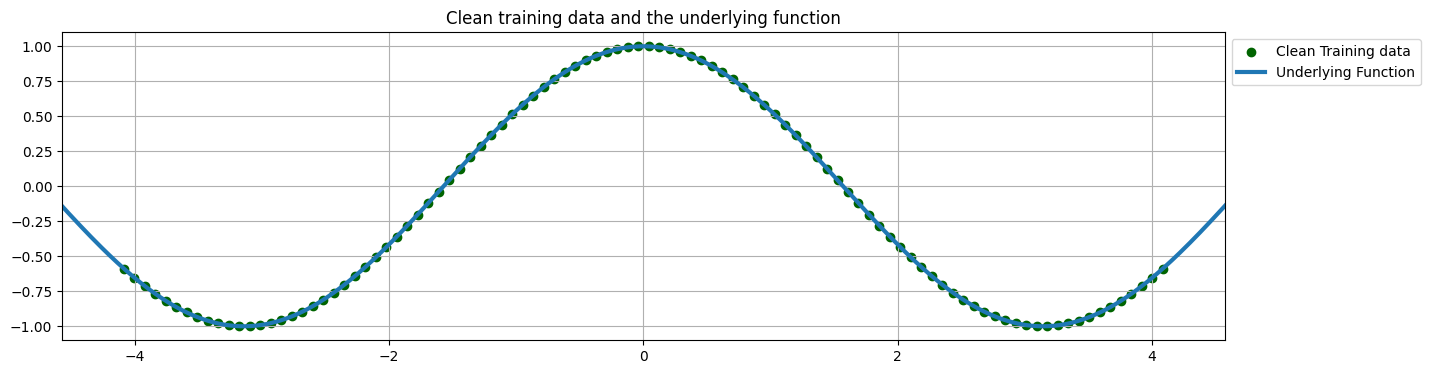

In [8]:
#@title Visualize training data
visualization_train_kwargs = {'marker':'o',
                              'linewidth':1,
                              'color':'darkgreen',
                              'label':'Clean Training data'}
visualize_samples_list = [(X_train,
                           Y_train_true,
                           visualization_train_kwargs)]
zooming_factor=2.2 # better zooming factor
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization/zooming_factor,
                  title='Clean training data and the underlying function')

The training inputs form an evenly spaced grid over $[-1.3\pi, 1.3\pi]$.

## Basic Clean Test Set
Now let's create a test set that covers inputs beyond the observed interval during training. For the basic clean test set $\mathcal{D}_{test}$, we create $n_{test}=200$ samples with $x\in[-3\pi,3\pi]$ and store them in the following variables.

```
# X_test       # test points input
# Y_test_true  # test points clean label
```

In [9]:
n_test = 200
domain_test = np.pi * np.array([-3, 3])
X_test, Y_test_true = sample_cosine(n_test,
                                    domain_test)

let's visually inspect our clean test and training data

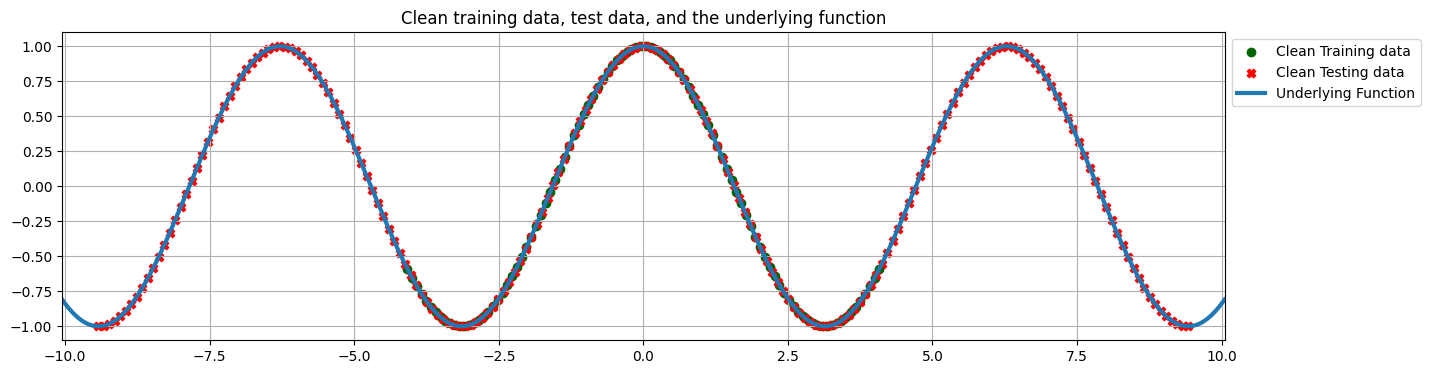

In [10]:
visualization_test_kwargs={'marker':'X',
                           'linewidth':1,
                           'color':'red',
                           'label':'Clean Testing data'}
# update visualization list
visualize_samples_list.append(
    (X_test,
     Y_test_true,
     visualization_test_kwargs))
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization,
                  title='Clean training data, test data, and the underlying function')

## Homoscedastic Gaussian Noise on the Training Set
Datasets are commonly noisy and this noise can be due to various reasons, for instance because of the measurement errors. So, a more realistic dataset will contain some noise in the labels. We will first create a dataset containing *homoscedastic* label noise -- a noise independent of the sample. For this, we choose an additive Gaussian noise $\mathcal{N}(0,\sigma^2)$ with variance $\sigma^2=0.01$. We call the dataset with the homoscedastic noise $\mathcal{D}^{homo}$. It contains the same input samples as that of $\mathcal{D}$ but the corresponding labels $y$ are generated with additive gaussian noise and stored in the following variable.

```
# Y_train_hom  # labels with homoscedastic additive Gaussian noise
```

In [11]:
noise_std = 0.1
# sample again with noise
X_train, Y_train_hom = sample_cosine(n_train,
                                     domain_train,
                                     gaussian_noise_std=noise_std)

Now, let us visualize the training data with homoscedastic label noise this time.

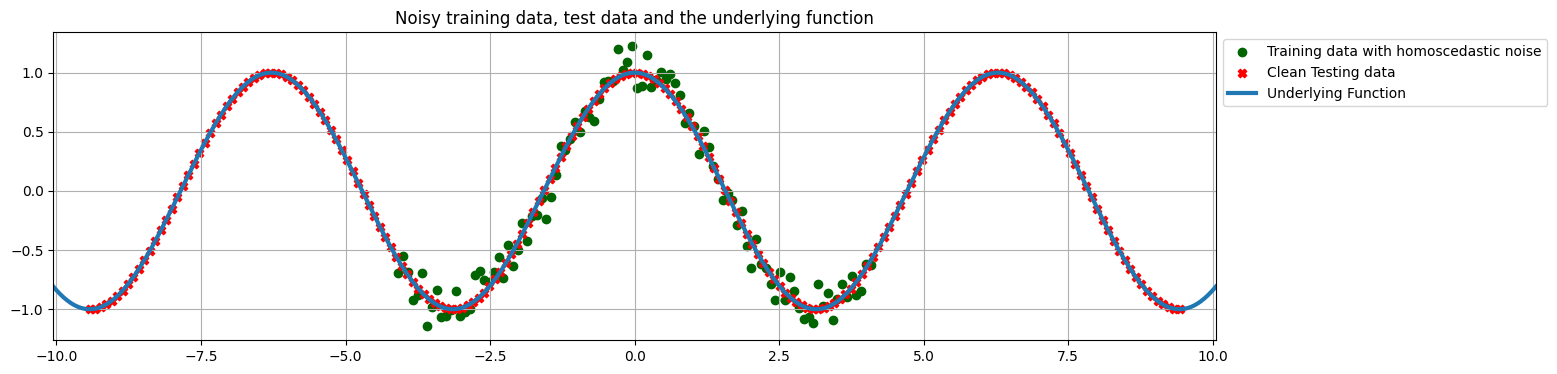

In [12]:
# update visualization information
visualization_train_kwargs['label']='Training data with homoscedastic noise'
visualize_samples_list[0]=(X_train,
                           Y_train_hom,
                           visualization_train_kwargs)
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization,
                  title='Noisy training data, test data and the underlying function')

## Heteroscedastic Noise on the Training Set
We then create another dataset, but this time, containing *heteroscedastic* label noise -- a noise that is dependent on the sample. It is common for the label noise to be dependent on (specifically proportional to) the magnitude for continuous labels. For this reason, we choose a *multiplicative* Gaussian noise $\mathcal{N}(\mu,\sigma^2)$ with mean $\mu=1$ and variance $\sigma^2=0.04$. We call the dataset with the heteroscedastic noise $\mathcal{D}^{het}$. It contains the same input samples as that of $\mathcal{D}$ but the corresponding labels $y$ are generated with multiplicative gaussian noise and stored in the following variable.

```
# Y_train_het  # labels with heteroscedastic multiplicative Gaussian noise
```

Equivalently, $y=\cos(x)(1+0.2\epsilon)$ with $\epsilon\sim\mathcal N(0,1)$. Thus $\mathbb E[y\mid x]=\cos(x)$ and $\operatorname{Var}(y\mid x)=0.04\cos^2(x)$: the conditional standard deviation is $0.2|\cos(x)|$. At zeros of the cosine, the observation is deterministic in this toy model.


In [13]:
noise_std = 0.2
noise_mean = 1
noise_fun = lambda noise,x,y: (noise_std * noise + noise_mean - 1) * y
X_train, Y_train_het = sample_cosine(n_train,
                                     domain_train,
                                     heteroscedastic_noise_fun=noise_fun)

Now, let us visualize the training data with heteroscedastic label noise this time.

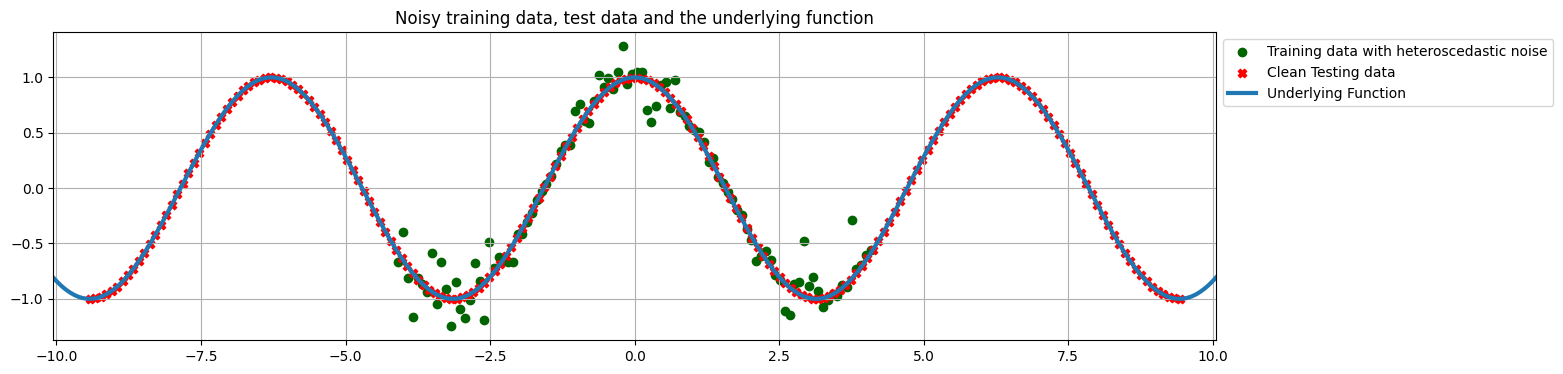

In [14]:
# update visualization information
visualization_train_kwargs['label']='Training data with heteroscedastic noise'
visualize_samples_list[0]=(X_train,
                           Y_train_het,
                           visualization_train_kwargs)
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization,
                  title='Noisy training data, test data and the underlying function')

The conditional noise standard deviation is largest when the cosine is close to $1$ or $-1$ and smallest near its zeros. Judge this from vertical residuals, not from the apparent width of the point cloud along the curve.

# Risk Minimization

In a regularized risk minimization scheme, we train a model parametrized by $\mathbf{\theta}$, on a training set $\mathcal{D}=\{(x_i,y_i)\}_{i=1}^{n}$, using the following minimization:

$$
\begin{aligned}
\mathbf{\theta}^*
&=\operatorname*{arg\,min}_{\mathbf{\theta}}
\left[\mathcal L(\mathcal D)+\Omega(\mathbf{\theta})\right]\\
&=\operatorname*{arg\,min}_{\mathbf{\theta}}
\left[\sum_{i=1}^{n}l(f_\theta(x_i),y_i)+\Omega(\mathbf{\theta})\right].
\end{aligned}
\tag{1}
$$

where $\mathcal{L}$ is the total loss function operating on the whole training set, $l$ is the sample loss function operating on individual training pairs $(x_i,y_i)$ and $\Omega$ is a regularization cost function.

It is common to use the average loss $\frac{1}{n}\sum_{i=1}^{n}l(f_\theta(x_i),y_i)$ instead of a sum. If a regularizer is included, its coefficient must also be scaled consistently to preserve the same objective.

## Training a Multi-Layer Perceptron (MLP)
Initially, we train a MLP, also known as fully-connected network, parametrized by its weights and biases $\mathbf{\theta}$. We use three hidden layers of size 100,40,100 units and the Rectified Linear Unit (ReLU), $\max(0,h)$, as the activation function. We use mean squared error (MSE). The baseline below does **not** implement weight decay: it is the unregularized case $\Omega(\theta)=0$ of the general expression above. Throughout this practical, we use Jax as the framework to implement our deep networks.

### Jax Deep Learning Framework
JAX provides a NumPy-like API, automatic differentiation, and just-in-time compilation for CPU and accelerators. Use `jax.numpy` for differentiable calculations; use NumPy for data creation and plotting. See the [JAX documentation](https://docs.jax.dev/en/latest/).

Let us first import the necessary Jax libraries.

In [15]:
import time

import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, value_and_grad
from jax import random
from jax import nn
from jax.example_libraries import optimizers

from functools import partial

# initialize the random generator
key = random.PRNGKey(rand_seed)

print("JAX version:", jax.__version__, "| Devices:", jax.devices())

JAX version: 0.7.2 | Devices: [CudaDevice(id=0), CudaDevice(id=1)]


Next, we define the configuration of the fully-connected (FC) network:

In [16]:
# standard network's configurations
input_dim = X_train.shape[1]
output_dim = Y_train_true.shape[1]
layers_width = [100, 40, 100]
num_epochs = 1000
step_size = 1e-2

Now, we define two python functions; one for initializing the parameters of a FC *layer* and another for the feed-forward computation of a FC *layer*.

In [17]:
# Initialize the parameters of a standard fully-connected layer
def standard_fc_layer_init(input_dim, output_dim, key, scale=1e-2):
    keys = random.split(key, 2) # key: JAX random key
    weights = random.normal(keys[0], (output_dim, input_dim)) * scale
    biases  = random.normal(keys[1], (output_dim, 1)) * scale
    return weights, biases

In [18]:
# Forward pass of a standard fully-connected layer
def standard_fc_layer_forward(input, weights, biases):
    return jnp.dot(weights, input) + biases

Next, we define two python functions; one for initializing the parameters of a FC *network* and another for the feed-forward computation of a FC *network*.

In [19]:
# Initialize A standard fully-connected network
def standard_fc_network_init(input_dim, layers_width, output_dim, key):
    network_feature_dims = [input_dim, *layers_width, output_dim]
    number_of_layers = len(network_feature_dims[:-1])
    keys = random.split(key, number_of_layers)
    params = [standard_fc_layer_init(network_feature_dims[i],
                                    network_feature_dims[i+1],
                                    keys[i])
                for i in range(number_of_layers)]
    return params

In [20]:
# Forward pass of a standard fully-connected network
def standard_fc_network_forward(input, params, is_classification=False):
    representation = input
    for weights,biases in params[:-1]:
        representation = nn.relu(standard_fc_layer_forward(representation, weights, biases))
    representation = standard_fc_layer_forward(representation,params[-1][0], params[-1][1])
    # params[-1][0] means weights of last layer
    # params[-1][1] means biases of last layer 

    if is_classification:
        # Classes are rows and examples are columns.
        return nn.log_softmax(representation, axis=0)

    return representation

In the following, we define a python function corresponding to the mean squared error (MSE) loss, as

$$
\mathcal{L}(\mathcal{D})=\frac{1}{n}\sum_{i=1}^{n}l(f_\theta(x_i),y_i)=\frac{1}{n}\sum_{i=1}^{n}(f_\theta(x_i)-y_i)^2
$$



In [21]:
@jit
def loss_mse(params, X, Y):
    """Mean squared error; predictions and targets must have the same shape."""
    preds = standard_fc_network_forward(X, params)
    if preds.shape != Y.shape:
        raise ValueError(f"Prediction shape {preds.shape} does not match target shape {Y.shape}.")
    return jnp.mean((preds - Y) ** 2)

Finally, we implement the code necessary for optimizing the network's parameters using the training data.

In [22]:
# The optimizer functions are explicit static arguments: changing the optimizer
# or its learning rate cannot silently reuse a stale global captured by JIT.
@partial(jit, static_argnames=("loss", "opt_update_fn", "get_params_fn"))
def update(step, params, X, Y, opt_state, loss, opt_update_fn, get_params_fn):
    value, grads = value_and_grad(loss)(params, X, Y)
    opt_state = opt_update_fn(step, grads, opt_state)
    return get_params_fn(opt_state), opt_state, value

In [23]:
def run_training_loop(num_epochs, opt_state, X, Y, X_test, Y_test, num_layers, loss):
    """Full-batch training from a fresh optimizer state (one step per epoch).

    Training MSE is measured against the supplied (possibly noisy) labels.
    Test MSE is measured against the clean curve, both inside and outside
    the training-input interval. Do not use this test curve for model selection.
    """
    train_loss, train_mse, test_mse = [], [], []
    params = get_params(opt_state)
    loss_eval = jit(loss)

    def record():
        values = (loss_eval(params, X.T, Y.T),
                  loss_mse(params[:num_layers], X.T, Y.T),
                  loss_mse(params[:num_layers], X_test.T, Y_test.T))
        values = tuple(float(v) for v in values)  # Synchronize device work.
        if not np.all(np.isfinite(values)):
            raise FloatingPointError("Non-finite loss/MSE. Check the loss and learning rate.")
        for history, value in zip((train_loss, train_mse, test_mse), values):
            history.append(value)
            # here history is referring to train_loss, train_mse and test_mse as a tuple
            # and it is appending the values so this is adding in all train_loss, train_mse, test_mse simultaneously.
    record() # record is been used twice
    print(f"Starting loss: {train_loss[-1]:.6f} | Train MSE: {train_mse[-1]:.6f}")
    for epoch in range(num_epochs):
        start_time = time.perf_counter()
        params, opt_state, _ = update(epoch, params, X.T, Y.T, opt_state,
                                      loss, opt_update, get_params)
        record()  # All three metrics refer to the updated parameters.
        if epoch == 0 or (epoch + 1) % 200 == 0:
            print(f"Epoch {epoch + 1} | T: {time.perf_counter() - start_time:.4f}s"
                  f" | Train loss: {train_loss[-1]:.6f}"
                  f" | Train MSE: {train_mse[-1]:.6f}"
                  f" | Clean-test MSE (all): {test_mse[-1]:.6f}")

    pred = np.asarray(standard_fc_network_forward(X_test.T, params[:num_layers])).T
    inside = (X_test[:, 0] >= X[:, 0].min()) & (X_test[:, 0] <= X[:, 0].max())
    for label, mask in (("interpolation", inside), ("extrapolation", ~inside)):
        if np.any(mask):
            mse = np.mean((pred[mask] - Y_test[mask]) ** 2)
            print(f"Final clean-test MSE ({label}): {mse:.6f}")
    return params, train_loss, train_mse, test_mse

In [24]:
def visualize_predictions(Y_test_pred, title_text, X_train=None, Y_train=None,
                          sigma_param=None, uncertainty_label="Aleatoric: mean ± 2 SD",
                          total_sigma_param=None):
    """Plot bands in standard-deviation units, without clipping their extent.

    A mean ± 2 SD band is not automatically a calibrated 95% interval,
    particularly when the predictive distribution is a non-Gaussian mixture.
    """
    mean = np.asarray(Y_test_pred).reshape(-1)
    if mean.size != X_test.shape[0]:
        raise ValueError("One prediction is required per test input.")
    fig, ax = plt.subplots(figsize=(15, 4))
    curve_x = np.linspace(domain_test[0], domain_test[1], 1000)
    ax.plot(curve_x, np.cos(curve_x), linewidth=3, label="Underlying function")
    ax.plot(X_test.ravel(), mean, linewidth=2, label="Predicted mean")
    if total_sigma_param is not None:
        total_std = np.broadcast_to(np.asarray(total_sigma_param).reshape(-1), mean.shape)
        ax.fill_between(X_test.ravel(), mean - 2*total_std, mean + 2*total_std,
                        alpha=0.15, label="Total predictive: mean ± 2 SD")
    if sigma_param is not None:
        std = np.broadcast_to(np.asarray(sigma_param).reshape(-1), mean.shape)
        if np.any(std < 0) or not np.all(np.isfinite(std)):
            raise ValueError("Standard deviations must be finite and nonnegative.")
        ax.fill_between(X_test.ravel(), mean - 2*std, mean + 2*std,
                        alpha=0.3, label=uncertainty_label)
    if X_train is not None and Y_train is not None:
        ax.scatter(np.asarray(X_train).ravel(), np.asarray(Y_train).ravel(),
                   marker="o", s=18, label="Training observations")
    ax.set(xlabel="x", ylabel="y", title=title_text)
    ax.legend(bbox_to_anchor=(1, 1), loc="upper left")
    ax.grid()
    fig.tight_layout()
    return fig, ax

With everything in place, now, let us launch the training for the clean dataset and visualize the learnt function.

In [25]:
# Initialize the network parameters
params = standard_fc_network_init(input_dim,
                                  layers_width,
                                  output_dim,
                                  key)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params)

params,\
train_loss,\
train_mse,\
test_mse = run_training_loop(num_epochs,
                             opt_state,
                             X_train,
                             Y_train_true,
                             X_test,
                             Y_test_true,
                             len(layers_width)+1,
                             loss_mse)

Starting loss: 0.554691 | Train MSE: 0.554691
Epoch 1 | T: 0.7665s | Train loss: 0.547126 | Train MSE: 0.547126 | Clean-test MSE (all): 0.502733
Epoch 200 | T: 0.0022s | Train loss: 0.000345 | Train MSE: 0.000345 | Clean-test MSE (all): 0.747393
Epoch 400 | T: 0.0024s | Train loss: 0.000040 | Train MSE: 0.000040 | Clean-test MSE (all): 1.245358
Epoch 600 | T: 0.0024s | Train loss: 0.000172 | Train MSE: 0.000172 | Clean-test MSE (all): 1.463654
Epoch 800 | T: 0.0023s | Train loss: 0.000087 | Train MSE: 0.000087 | Clean-test MSE (all): 1.646604
Epoch 1000 | T: 0.0023s | Train loss: 0.000093 | Train MSE: 0.000093 | Clean-test MSE (all): 1.751312
Final clean-test MSE (interpolation): 0.000093
Final clean-test MSE (extrapolation): 3.072407


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Standard\\, FC\\, network}$ trained on $\\bf{clean\\, training\\, data}$'}, xlabel='x', ylabel='y'>)

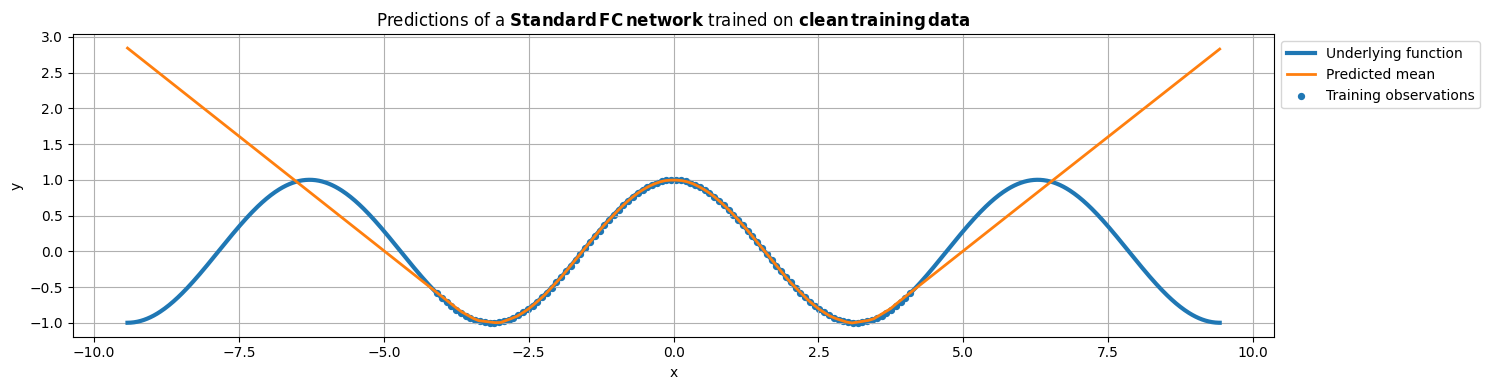

In [26]:
Y_test_pred = standard_fc_network_forward(X_test.T, params)
visualize_predictions(Y_test_pred,
                     r'Predictions of a $\bf{Standard\, FC\, network}$'
                     r' trained on $\bf{clean\, training\, data}$',
                     X_train, Y_train_true)

Inspect the fit inside the training range $[-1.3\pi,1.3\pi]$ and compare it with the extrapolation outside this range. The training interval spans **1.3 periods**, not exactly one. A ReLU network has no explicit periodic inductive bias, so a good fit in the observed range does not establish reliable extrapolation.

Now train the same architecture on labels with homoscedastic noise.

**Answer from the saved run.** The deterministic network fits the observed interval very closely: clean interpolation MSE is 0.000093. Extrapolation MSE is 3.072407, despite the excellent training fit. The model does not learn a periodic continuation from this limited interval; a ReLU network can extend its fitted segments incorrectly outside the data.


In [27]:
# Initialize the network parameters
params_hom = standard_fc_network_init(input_dim,
                                      layers_width,
                                      output_dim,
                                      key)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_hom)

params_hom,\
train_loss_hom,\
train_mse_hom,\
test_mse_hom = run_training_loop(num_epochs,
                                 opt_state,
                                 X_train,
                                 Y_train_hom,
                                 X_test,
                                 Y_test_true,
                                 len(layers_width)+1,
                                 loss_mse)

Starting loss: 0.580514 | Train MSE: 0.580514
Epoch 1 | T: 0.5062s | Train loss: 0.573048 | Train MSE: 0.573048 | Clean-test MSE (all): 0.502734
Epoch 200 | T: 0.0026s | Train loss: 0.010770 | Train MSE: 0.010770 | Clean-test MSE (all): 0.479377
Epoch 400 | T: 0.0027s | Train loss: 0.009893 | Train MSE: 0.009893 | Clean-test MSE (all): 0.460914
Epoch 600 | T: 0.0022s | Train loss: 0.009539 | Train MSE: 0.009539 | Clean-test MSE (all): 0.508277
Epoch 800 | T: 0.0028s | Train loss: 0.009049 | Train MSE: 0.009049 | Clean-test MSE (all): 0.487325
Epoch 1000 | T: 0.0023s | Train loss: 0.009420 | Train MSE: 0.009420 | Clean-test MSE (all): 0.512618
Final clean-test MSE (interpolation): 0.004045
Final clean-test MSE (extrapolation): 0.896278


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Standard\\, FC\\, network}$ trained on training data with $\\bf{homoscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

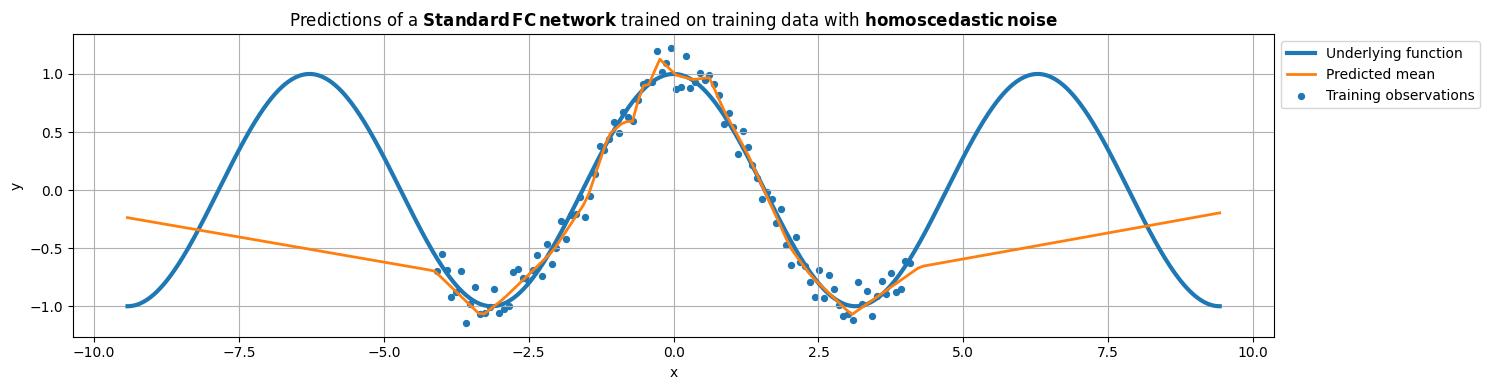

In [28]:
Y_test_pred_hom = standard_fc_network_forward(X_test.T, params_hom)
visualize_predictions(Y_test_pred_hom,
                     r'Predictions of a $\bf{Standard\, FC\, network}$'
                     r' trained on training data with $\bf{homoscedastic\, noise}$',
                     X_train, Y_train_hom)

Compare the fit with the clean-data result. Does the network follow some of the noise? This can happen, but its extent depends on the data realization, optimization, and model capacity.

Next, use the labels with heteroscedastic noise.

**Answer from the saved run.** With homoscedastic noise, training MSE is 0.009420 and clean interpolation MSE is 0.004045, compared with 0.000093 for clean-data training. The plot shows small bends following noisy observations around the peak and troughs. This suggests some fitting of the noise, although it is not exact interpolation of every label. Extrapolation MSE is 0.896278; the lower value than the clean-data run is specific to these fits and does not establish that adding noise improves extrapolation in general.


In [29]:
# Initialize the network parameters
params_het = standard_fc_network_init(input_dim,
                                      layers_width,
                                      output_dim,
                                      key)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_het)

params_het,\
train_loss_het,\
train_mse_het,\
test_mse_het = run_training_loop(num_epochs,
                                 opt_state,
                                 X_train,
                                 Y_train_het,
                                 X_test,
                                 Y_test_true,
                                 len(layers_width)+1,
                                 loss_mse)

Starting loss: 0.562691 | Train MSE: 0.562691
Epoch 1 | T: 0.5052s | Train loss: 0.555696 | Train MSE: 0.555696 | Clean-test MSE (all): 0.502733
Epoch 200 | T: 0.0026s | Train loss: 0.020579 | Train MSE: 0.020579 | Clean-test MSE (all): 0.615803
Epoch 400 | T: 0.0025s | Train loss: 0.020097 | Train MSE: 0.020097 | Clean-test MSE (all): 0.576098
Epoch 600 | T: 0.0022s | Train loss: 0.019077 | Train MSE: 0.019077 | Clean-test MSE (all): 0.520057
Epoch 800 | T: 0.0025s | Train loss: 0.019209 | Train MSE: 0.019209 | Clean-test MSE (all): 0.513616
Epoch 1000 | T: 0.0023s | Train loss: 0.019066 | Train MSE: 0.019066 | Clean-test MSE (all): 0.515963
Final clean-test MSE (interpolation): 0.005692
Final clean-test MSE (extrapolation): 0.900904


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Standard\\, FC\\, network}$ trained on training data with $\\bf{heteroscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

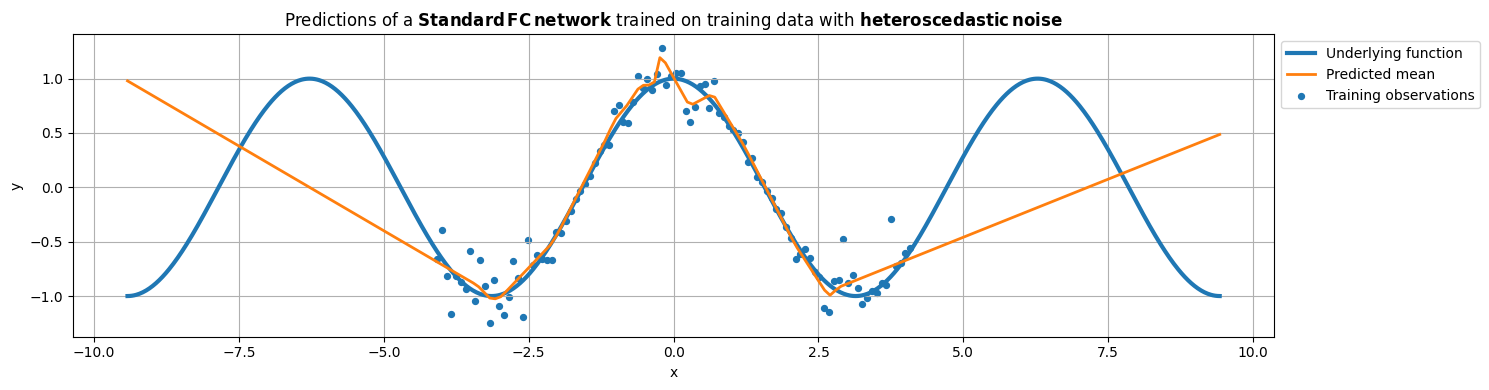

In [30]:
Y_test_pred_het = standard_fc_network_forward(X_test.T,
                                              params_het)
visualize_predictions(Y_test_pred_het,
                     r'Predictions of a $\bf{Standard\, FC\, network}$'
                     r' trained on training data with $\bf{heteroscedastic\, noise}$',
                     X_train, Y_train_het)

Compare both noisy-data fits. Do not assume that heteroscedastic noise must cause more overfitting: these two datasets also have different average noise variances. Describe what your run actually shows.

**Answer from the saved run.** Heteroscedastic training gives training MSE 0.019066, clean interpolation MSE 0.005692 and extrapolation MSE 0.900904. The homoscedastic values are 0.009420, 0.004045 and 0.896278. Both fits broadly follow the cosine inside the data range and fail to recover periodicity outside. The heteroscedastic fit shows local deviations around the central peak, where its generating noise is large, while observations near cosine zeros have much less noise. Its slightly higher clean interpolation error is not proof that heteroscedastic noise inherently causes more overfitting; the datasets have different noise magnitudes and realizations.


# Training with an Assumed Label-Noise Distribution

In the lectures, we discussed that one way to model aleatoric uncertainty is using maximum likelihood estimation (MLE) in tandem with a model that can output probability distributions. Here, we are going to follow this idea to see how well this approach can predict the aleatoric uncertainty.

## Modelling Aleatoric Uncertainty: Learning to predict a fixed (homoscedastic) uncertainty
For a maximum likelihood estimation we need to devise a likelihood function. Let's assume a Gaussian likelihood function, parametrized by a deep network to give its mean and variance, given an input. In this first part, we assume the deep network produces a fixed variance independent of the input sample while the mean is dependent on the input sample. That is, our likelihood function has the following form:

$$
P(y\mid\mathbf{x};\mathbf{\theta},\sigma)=\mathcal{N}(y;f_{\mathbf{\theta}}(\mathbf{x}),\sigma^2).
$$

Think(!) how this is the same as assuming an additive Gaussian noise with a fixed variance on the labels.

First, we introduce a scalar controlling the shared standard deviation and initialize the mean network as before.

The scalar $s$ stores a trainable log standard deviation, not a variance. For numerical protection on the noise-free dataset, the implementation uses $s_{\mathrm{eff}}=\max(s,\log\sigma_{\min})$ and $\sigma=\exp(s_{\mathrm{eff}})$ with $\sigma_{\min}=10^{-3}$. This is an explicit lower bound on the likelihood standard deviation, not an estimate of epistemic uncertainty. Use the same transformation for training and plotting.


**Additive-noise interpretation:** $y=f_	heta(x)+\epsilon$, with $\epsilon\sim\mathcal N(0,\sigma^2)$ independent of $x$, gives exactly the stated Gaussian likelihood. A constant $\sigma$ makes this noise homoscedastic.


In [31]:
# A small, explicit lower bound prevents a zero-variance Gaussian likelihood.
min_likelihood_std = 1e-3

def homoscedastic_log_std(params):
    return jnp.maximum(params[-1], jnp.log(min_likelihood_std))

# One trainable scalar for the log standard deviation (not the variance).
sigma_param = jnp.array(jnp.log(0.2))

# Initialize the network parameters that will produce the mean of the likelihood's Gaussian
params_homo_model_clean_data = standard_fc_network_init(input_dim,
                                                        layers_width,
                                                        output_dim,
                                                        key)

# Append the log-standard-deviation parameter, not the standard deviation.
params_homo_model_clean_data.append(sigma_param)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_homo_model_clean_data)

Choose the network parameters and shared scale to maximize the likelihood:

$$
(\theta^*,s^*)=\operatorname*{arg\,max}_{\theta,s}
\prod_{i=1}^n\mathcal N\!\left(y_i;f_\theta(x_i),\exp(2s_{\mathrm{eff}})\right).
$$

Take the negative logarithm and write the equivalent minimization objective. Derive the sum form first, then divide the **entire objective** by $n$ for the implementation. Retain the Gaussian normalizing constant so numerical loss values are comparable.

### Derivation 1: homoscedastic Gaussian likelihood
Let $r_i=y_i-f_\theta(x_i)$ and $\sigma=e^{s_{\mathrm{eff}}}$. The variance is $\sigma^2=e^{2s_{\mathrm{eff}}}$. The Gaussian density for one example is
$$
\mathcal N_i=\frac{1}{\sqrt{2\pi}\,e^{s_{\mathrm{eff}}}}
\exp\left(-\frac{r_i^2}{2e^{2s_{\mathrm{eff}}}}\right).
$$
Taking logarithms gives
$$
\log\mathcal N_i=-\frac12\log(2\pi)-s_{\mathrm{eff}}
-\frac{r_i^2}{2e^{2s_{\mathrm{eff}}}}.
$$
Maximizing the product of independent Gaussian densities is equivalent to minimizing the sum of negative log densities:
$$
-\log\prod_{i=1}^n\mathcal N_i
=\sum_{i=1}^n\left[\frac12\log(2\pi)+s_{\mathrm{eff}}
+\frac{r_i^2}{2e^{2s_{\mathrm{eff}}}}\right].
$$
Dividing the entire objective by $n$ gives the mean negative log likelihood:
$$
\begin{aligned}
\mathcal L(\theta,s)
&=\frac1n\sum_{i=1}^n\left[\frac12\log(2\pi)+s_{\mathrm{eff}}
+\frac{(y_i-f_\theta(x_i))^2}{2e^{2s_{\mathrm{eff}}}}\right]\\
&=\frac12\log(2\pi)+s_{\mathrm{eff}}
+\frac12e^{-2s_{\mathrm{eff}}}\operatorname{MSE}_{\mathrm{train}}.
\end{aligned}
$$
Here $s_{\mathrm{eff}}=\max(s,\log 10^{-3})$ is the effective log standard deviation. The standard deviation is $e^{s_{\mathrm{eff}}}$ and the variance is $e^{2s_{\mathrm{eff}}}$. The squared-residual denominator must contain the **variance**, which explains the factor of 2 in the exponent. This matches the implemented loss.


Implement the mean negative log likelihood below. Use `homoscedastic_log_std(params)` for the effective log standard deviation, including the documented lower bound. Keep prediction and target shapes identical. A negative Gaussian negative log likelihood is possible: densities, unlike probabilities of events, can exceed one.

In [32]:
def loss_mle_homoscedastic(params, X, Y):
    """TODO: implement the mean Gaussian negative log likelihood.

    params[:-1] contains the mean network. Obtain the effective log standard
    deviation with homoscedastic_log_std(params). Include the normalizing
    constant, average over examples, and return one differentiable scalar.
    """
    preds = standard_fc_network_forward(X, params[:-1]) # f_{\theta}(x_i)
    if preds.shape != Y.shape:
        raise ValueError("Predictions and targets must have identical shapes.")
    residuals = Y - preds
    MSE = jnp.mean(residuals**2)
    s_eff = homoscedastic_log_std(params)
    constant = 1/2*jnp.log(2*jnp.pi) 
    
    return constant + s_eff + 0.5 * jnp.exp(-2 * s_eff) * MSE

Starting loss: 6.243139 | Train MSE: 0.554691
Epoch 1 | T: 0.7281s | Train loss: 6.022954 | Train MSE: 0.547110 | Clean-test MSE (all): 0.502732
Epoch 200 | T: 0.0025s | Train loss: -0.773132 | Train MSE: 0.000469 | Clean-test MSE (all): 0.671016
Epoch 400 | T: 0.0027s | Train loss: -1.572839 | Train MSE: 0.000816 | Clean-test MSE (all): 1.364238
Epoch 600 | T: 0.0022s | Train loss: -1.719407 | Train MSE: 0.001800 | Clean-test MSE (all): 1.131701
Epoch 800 | T: 0.0027s | Train loss: -2.133076 | Train MSE: 0.000778 | Clean-test MSE (all): 1.688465
Epoch 1000 | T: 0.0030s | Train loss: -2.213295 | Train MSE: 0.000412 | Clean-test MSE (all): 0.682405
Final clean-test MSE (interpolation): 0.000296
Final clean-test MSE (extrapolation): 1.196978
The final trained homoscedastic standard deviation for clean data is:  0.037757784


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Homoscedastic\\, FC\\, network}$ trained on training data with $\\bf{clean\\, labels}$'}, xlabel='x', ylabel='y'>)

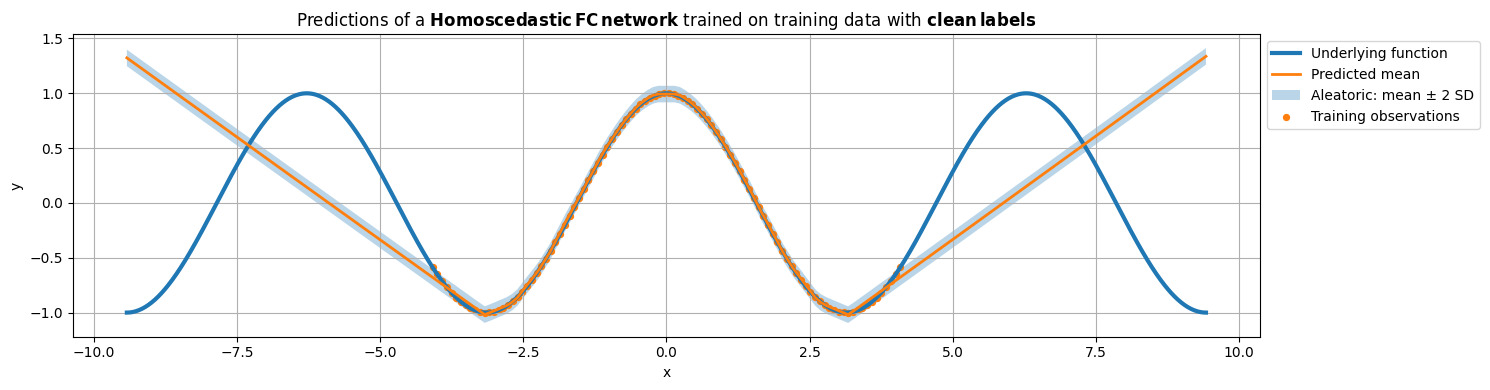

In [33]:
params_homo_model_clean_data,\
train_loss_homo_model_clean_data,\
train_mse_homo_model_clean_data,\
test_mse_homo_model_clean_data = run_training_loop(num_epochs,
                                                   opt_state, X_train,
                                                   Y_train_true, X_test,
                                                   Y_test_true,
                                                   len(layers_width)+1,
                                                   loss_mle_homoscedastic)

sigma_param = jnp.exp(homoscedastic_log_std(params_homo_model_clean_data))
print('The final trained homoscedastic standard deviation'
      ' for clean data is: ',
      sigma_param)

Y_test_pred_homo_model_clean_data = standard_fc_network_forward(X_test.T,
                                                                params_homo_model_clean_data[:-1])

visualize_predictions(Y_test_pred_homo_model_clean_data,
                     r'Predictions of a $\bf{Homoscedastic\, FC\, network}$'
                     r' trained on training data with $\bf{clean\, labels}$',
                     X_train,
                     Y_train_true,
                     sigma_param)

How small is the learned standard deviation on clean data? For a fixed mean function, the unconstrained optimum satisfies $\sigma^2=\mathrm{MSE}_{\mathrm{train}}$. If the network exactly interpolates all labels, the Gaussian likelihood is unbounded as $\sigma\to0$: there is no finite, positive-variance MLE. The explicit lower bound prevents this numerical degeneracy, but it does not make the fit calibrated. A poor mean fit can instead inflate the learned scale.

Now fit the data with homoscedastic additive noise.

**Answer from the saved run.** The learned clean-data standard deviation is 0.037758, well above the imposed floor of 0.001. The final training MSE is 0.000412, so the fixed-mean optimum would have standard deviation approximately $\sqrt{0.000412}=0.02030$. The learned scale has not reached that fixed-mean optimum during joint finite-step training. It reflects residual mean error/optimization, not true observation noise in this clean dataset. Interpolation MSE is 0.000296, whereas extrapolation MSE is 1.196978.


Starting loss: 6.565927 | Train MSE: 0.580514
Epoch 1 | T: 0.5782s | Train loss: 6.340560 | Train MSE: 0.573032 | Clean-test MSE (all): 0.502732
Epoch 200 | T: 0.0024s | Train loss: -0.549560 | Train MSE: 0.011438 | Clean-test MSE (all): 0.654692
Epoch 400 | T: 0.0028s | Train loss: -0.867132 | Train MSE: 0.009638 | Clean-test MSE (all): 0.473699
Epoch 600 | T: 0.0027s | Train loss: -0.913888 | Train MSE: 0.009400 | Clean-test MSE (all): 0.471723
Epoch 800 | T: 0.0029s | Train loss: -0.939019 | Train MSE: 0.008951 | Clean-test MSE (all): 0.495549
Epoch 1000 | T: 0.0027s | Train loss: -0.964797 | Train MSE: 0.008498 | Clean-test MSE (all): 0.500750
Final clean-test MSE (interpolation): 0.003916
Final clean-test MSE (extrapolation): 0.875554
The final trained homoscedastic standard deviation for data with fixed additive Gaussian noise is:  0.09356373


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Homoscedastic\\, FC\\, network}$ trained on training data with $\\bf{homoscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

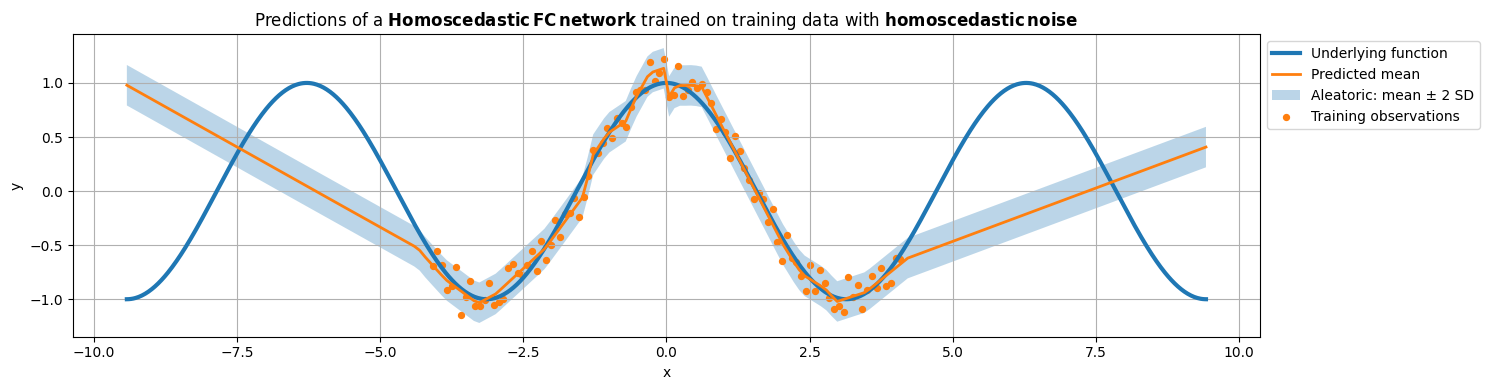

In [34]:
# One trainable scalar for the log standard deviation (not the variance).
sigma_param = jnp.array(jnp.log(0.2))

# Initialize the network parameters that will produce the mean of the likelihood's Gaussian
params_homo_model_homo_data = standard_fc_network_init(input_dim,
                                                       layers_width,
                                                       output_dim,
                                                       key)

# Append the log-standard-deviation parameter, not the standard deviation.
params_homo_model_homo_data.append(sigma_param)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_homo_model_homo_data)

params_homo_model_homo_data,\
train_loss_homo_model_homo_data,\
train_mse_homo_model_homo_data,\
test_mse_homo_model_homo_data = run_training_loop(num_epochs,
                                                  opt_state,
                                                  X_train,
                                                  Y_train_hom,
                                                  X_test,
                                                  Y_test_true,
                                                  len(layers_width)+1,
                                                  loss_mle_homoscedastic)

sigma_param = jnp.exp(homoscedastic_log_std(params_homo_model_homo_data))
print('The final trained homoscedastic standard deviation '
      'for data with fixed additive Gaussian noise is: ',
      sigma_param)

Y_test_pred_homo_model_homo_data = standard_fc_network_forward(X_test.T,
                                                               params_homo_model_homo_data[:-1])

visualize_predictions(Y_test_pred_homo_model_homo_data,
                     r'Predictions of a $\bf{Homoscedastic\, FC\, network}$'
                     r' trained on training data with $\bf{homoscedastic\, noise}$',
                     X_train,
                     Y_train_hom,
                     sigma_param)


Compare the learned standard deviation with the generating value $0.1$. Does the shaded band contain most training observations? Distinguish a useful visual check from a calibration test: these observations were used for fitting, and a flexible network can fit noise and underestimate the noise scale. Proper coverage assessment requires fresh noisy labels, preferably with interpolation and extrapolation reported separately. The clean test curve is not a set of draws from the noisy observation distribution.

Now fit the data with heteroscedastic label noise using the same fixed-variance model.

**Answer from the saved run.** The learned standard deviation is 0.093564, close to but about 6.4% below the generating value 0.1. Most training observations visually lie within the plotted mean $\pm2\sigma$ band; this is a visual observation, not a measured coverage percentage. The final training MSE is 0.008498, with clean interpolation MSE 0.003916. Some noise can be absorbed by the flexible mean network, helping explain the slightly low scale. These training observations cannot establish held-out coverage, and the clean cosine test curve is not a sample of noisy outcomes.


Starting loss: 6.343144 | Train MSE: 0.562691
Epoch 1 | T: 0.5825s | Train loss: 6.127964 | Train MSE: 0.555680 | Clean-test MSE (all): 0.502732
Epoch 200 | T: 0.0028s | Train loss: -0.398619 | Train MSE: 0.021039 | Clean-test MSE (all): 0.527385
Epoch 400 | T: 0.0023s | Train loss: -0.536685 | Train MSE: 0.019754 | Clean-test MSE (all): 0.523915
Epoch 600 | T: 0.0023s | Train loss: -0.564789 | Train MSE: 0.018902 | Clean-test MSE (all): 0.506788
Epoch 800 | T: 0.0023s | Train loss: -0.572448 | Train MSE: 0.018626 | Clean-test MSE (all): 0.535884
Epoch 1000 | T: 0.0023s | Train loss: -0.582135 | Train MSE: 0.018272 | Clean-test MSE (all): 0.551014
Final clean-test MSE (interpolation): 0.005072
Final clean-test MSE (extrapolation): 0.962866
The final trained homoscedastic standard deviation for data with variable (heteroscedastic) noise is:  0.13661475


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Homoscedastic\\, FC\\, network}$ trained on training data with $\\bf{heteroscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

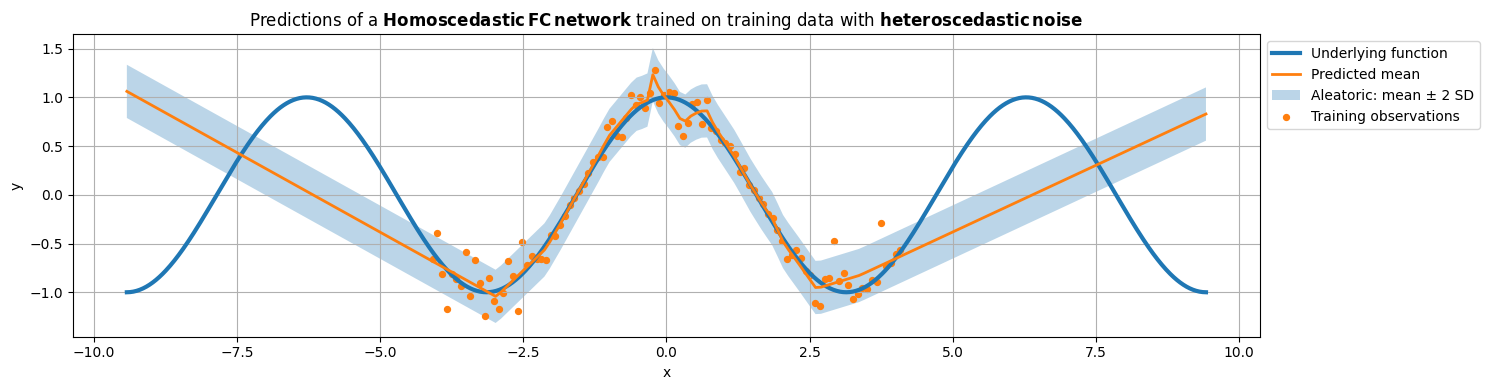

In [35]:
# One trainable scalar for the log standard deviation (not the variance).
sigma_param = jnp.array(jnp.log(0.2))

# Initialize the network parameters that will produce the mean of the likelihood's Gaussian
params_homo_model_het_data = standard_fc_network_init(input_dim,
                                                      layers_width,
                                                      output_dim,
                                                      key)

# Append the log-standard-deviation parameter, not the standard deviation.
params_homo_model_het_data.append(sigma_param)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_homo_model_het_data)

params_homo_model_het_data,\
train_loss_homo_model_het_data,\
train_mse_homo_model_het_data,\
test_mse_homo_model_het_data = run_training_loop(num_epochs,
                                                 opt_state,
                                                 X_train,
                                                 Y_train_het,
                                                 X_test,
                                                 Y_test_true,
                                                 len(layers_width)+1,
                                                 loss_mle_homoscedastic)

sigma_param = jnp.exp(homoscedastic_log_std(params_homo_model_het_data))
print('The final trained homoscedastic standard deviation '
      'for data with variable (heteroscedastic) noise is: ',
      sigma_param)

Y_test_pred_homo_model_het_data = standard_fc_network_forward(X_test.T, params_homo_model_het_data[:-1])

visualize_predictions(Y_test_pred_homo_model_het_data,
                     r'Predictions of a $\bf{Homoscedastic\, FC\, network}$'
                     r' trained on training data with $\bf{heteroscedastic\, noise}$',
                     X_train,
                     Y_train_het,
                     sigma_param)


Does one fixed standard deviation make sense everywhere when the true conditional standard deviation is $0.2|\cos(x)|$? Compare regions near the cosine's zeros with regions near its peaks. Explain how a shared scale can average over different local noise levels and mean-model errors. High overall training coverage does not establish correct local uncertainty.

Only the **homoscedastic likelihood** is implemented in this practical. Fitting a network that predicts an input-dependent likelihood variance is outside the present scope. Also, an aleatoric band is not expected to expand simply because an input is far from the training data: that requires a separate treatment of epistemic uncertainty.

**Answer from the saved run.** The shared learned standard deviation is 0.136615. The true standard deviation is $0.2|\cos(x)|$: it approaches zero at cosine zeros and reaches 0.2 near peaks/troughs. A single shared scale cannot reproduce both; relative to the generating noise it is too large near zeros and too small near extrema. It averages noise levels and mean-model errors. The clean interpolation MSE is 0.005072 and extrapolation MSE is 0.962866. Its band has constant width even outside the data range because this model estimates only a shared observation scale.


---
---
---


# Variational Inference for Deep Regression Networks
In this part of the practical we are interested in epistemic uncertainty estimation with deep networks based on the following paper.

[1] Blundell et al., ["Weight Uncertainty in Neural Networks"](https://proceedings.mlr.press/v37/blundell15.html), ICML 2015.

---



In order to model epistemic uncertainty, we can use Bayesian modelling to obtain a posterior distribution on model parameters:

$$
P(\mathbf{\theta}|\mathcal{D})= \frac{P(\mathcal{D}|\mathbf{\theta})P(\mathbf{\theta})}{P(\mathcal{D})}
$$




Using this posterior distribution, we can transfer the uncertainty in model parameters to uncertainty in predictive distribution, where, for a new test sample $\mathbf{x}$:



$$
P(y|\mathbf{x},\mathcal{D})=\int P(y|\mathbf{x},\mathbf{\theta})P(\mathbf{\theta}|\mathcal{D})d\theta.
$$



However, obtaining $P(\mathbf{\theta}|\mathcal{D})$ can be problematic due to the intractability of calculating $P(\mathcal{D})$. Thus, there are several techniques developed to approximate the posterior distribution $P(\mathbf{\theta}|\mathcal{D})$. One of these techniques is called Variational Inference (VI). In VI, we seek to identify another, simpler, distribution $Q_\omega(\theta)$, parametrized by $\omega$, that approximates $P(\theta|\mathcal{D})$. In VI, we can maximize the evidence lower bound (ELBO), or minimize a negated version, as follows (details provided in the course lectures and the VAE practical):




$$
\omega^*=\text{argmin}_{\omega} -\mathbb{E}_{Q_\omega(\theta)}[\log P(\mathcal{D}|\theta)]+\text{D}_{\text{KL}}(Q_\omega(\theta)||P(\theta))
$$



Assume the labels are conditionally independent given the inputs and weights. The inputs themselves are a fixed grid; they need not be independently sampled for this conditional likelihood to factorize:

$$
\omega^*=\operatorname*{arg\,min}_\omega
-\mathbb E_{Q_\omega(\theta)}\!\left[\sum_{i=1}^n\log P(y_i\mid x_i,\theta)\right]
+ D_{\mathrm{KL}}\!\left(Q_\omega(\theta)\Vert P(\theta)\right).
$$

Approximate the expectation by Monte Carlo samples from the weight distribution.

$$
\omega^*=\operatorname*{arg\,min}_\omega
\left[
-\frac{1}{S}\sum_{s=1}^{S}\sum_{i=1}^{n}\log P(y_i\mid x_i,\theta_s)
+D_{\mathrm{KL}}\!\left(Q_\omega(\theta)\Vert P(\theta)\right)
\right].
\tag{2}
$$


where, $\{\theta_s\}_{s=1}^{S}\sim Q_\omega(\theta)$.

Let us consider the following distributions:



$$
P(\theta)=\mathcal N(\mathbf 0_p,a^2I_p),\qquad a=10^{-2},
$$

$$
Q_{\omega=(\mu,\rho)}(\theta)=\mathcal N\!\left(\mu,\operatorname{diag}(\sigma^2)\right),
\qquad \sigma=\operatorname{softplus}(\rho),
$$

$$
P(y\mid x,\theta)=\mathcal N\!\left(y;f_\theta(x),c^2\right),\qquad c^2=1.
$$

These are the weight prior, approximate weight posterior, and conditional observation likelihood, respectively. The likelihood is **not** the posterior predictive distribution; the latter averages the likelihood over weights.

Here $p$ is the total number of scalar weights and biases, and $I_p$ is the identity matrix. The network outputs **one mean**, not both a mean and a variance: the observation variance $c^2$ is fixed in this part. Both weight covariance matrices are diagonal.

Following Blundell et al., optimize the unconstrained weight-scale parameter $\rho$ and obtain a positive weight standard deviation with the numerically stable `nn.softplus` function:



$$
\sigma=\text{log}(1+\exp(\rho))
$$



Plug these distributions into Equation (2), using one sampled network per full-batch gradient step ($S=1$). Expand the Gaussian log likelihood and the closed-form diagonal-Gaussian KL divergence. Include **all weights and biases** in the KL.

First derive the ordinary negative ELBO. Then introduce a coefficient $\beta=\texttt{kl\_weight}$ on the KL term to match the code. Explain the distinction between $\beta=1$ and the supplied $\beta=10^{-4}$.



$$
\widehat{\mathcal L}_\beta(\omega)
=-\sum_{i=1}^n\log P(y_i\mid x_i,\theta_\epsilon)
+\beta D_{\mathrm{KL}}\!\left(Q_\omega(\theta)\Vert P(\theta)\right),
\qquad \theta_\epsilon\sim Q_\omega.
$$

**Expand both terms in this expression.**

### TODO — Derivation 2: VI and the KL-weighted objective
Derive the Gaussian likelihood term and the diagonal-Gaussian KL term, substitute the reparameterized sample, and specify the reduction over training examples and over weight/bias coordinates. State which quantities are standard deviations and which are variances.

**Your derivation and interpretation of $\beta$:** 

The likelihood for each observation is
$$
P(y_i\mid x_i,\theta)
=\mathcal N(y_i;f_\theta(x_i),c^2).
$$

Taking the negative logarithm and summing over training examples (opened in the same form like in 1st TODO):
$$
-\log P(\mathcal D\mid\theta)
=
\frac{n}{2}\log(2\pi c^2)
+\frac{1}{2c^2}\sum_{i=1}^{n}
\left(y_i-f_\theta(x_i)\right)^2.
$$

The prior and approximate posterior are
$$
P(\theta)=\mathcal N(0,a^2I_p),
\qquad
Q_\omega(\theta)
=\mathcal N\left(\mu,\operatorname{diag}(\sigma^2)\right).
$$

Using
$$
D_{\mathrm{KL}}(Q_\omega\Vert P)
=\mathbb E_{Q_\omega}[\log Q_\omega(\theta)-\log P(\theta)],
$$
together with
$$
\mathbb E_{Q_\omega}[(\theta_j-\mu_j)^2]=\sigma_j^2,
\qquad
\mathbb E_{Q_\omega}[\theta_j^2]=\mu_j^2+\sigma_j^2,
$$
gives
$$
D_{\mathrm{KL}}(Q_\omega\Vert P)
=
\frac12\sum_{j=1}^{p}
\left[
\frac{\mu_j^2+\sigma_j^2}{a^2}
-1+\log\frac{a^2}{\sigma_j^2}
\right].
$$

The sum includes every scalar weight and bias in every layer.

The ordinary negative ELBO is
$$
\mathcal L_1(\omega)
=
-\mathbb E_{Q_\omega}[\log P(\mathcal D\mid\theta)]
+D_{\mathrm{KL}}(Q_\omega\Vert P).
$$

For one Monte Carlo sample ($S=1$), use the reparameterization
$$
\epsilon\sim\mathcal N(0,I_p),
\qquad
\sigma=\operatorname{softplus}(\rho),
\qquad
\theta_\epsilon=\mu+\sigma\odot\epsilon.
$$

Introducing the KL coefficient $\beta$, the sampled objective becomes
$$
\begin{aligned}
\widehat{\mathcal L}_\beta(\mu,\rho)
={}&\frac n2\log(2\pi c^2)\\
&+\frac{1}{2c^2}\sum_{i=1}^{n}
\left(
y_i-f_{\mu+\operatorname{softplus}(\rho)\odot\epsilon}(x_i)
\right)^2\\
&+\frac{\beta}{2}\sum_{j=1}^{p}
\left[
\frac{\mu_j^2+\operatorname{softplus}(\rho_j)^2}{a^2}
-1+\log\frac{a^2}{\operatorname{softplus}(\rho_j)^2}
\right].
\end{aligned}
$$

In this practical, $c^2=1$ and $a=10^{-2}$, hence $a^2=10^{-4}$.
The likelihood term is summed over training examples, and the KL
term is summed over all weight and bias coordinates. One sampled
network is shared across the full training batch. The KL is
computed analytically.

### Interpretation of $\beta$

For $\beta=1$, the objective is a Monte Carlo estimate of the
ordinary negative ELBO. In expectation,
$$
\mathcal L_1(\omega)
=
D_{\mathrm{KL}}\left(
Q_\omega(\theta)\Vert P(\theta\mid\mathcal D)
\right)
-\log P(\mathcal D).
$$
Since the evidence does not depend on $\omega$, minimizing this
objective approximates the Bayesian posterior.

For $\beta=10^{-4}$, the KL penalty is reduced by a factor of
$10{,}000$. This allows the approximate posterior to deviate more
from the prior to improve data fitting. It is a KL-weighted
objective, rather than the ordinary negative ELBO for the stated
model. Better uncertainty calibration is not guaranteed.

The quantities $a$, $c$, and $\sigma_j$ are standard deviations;
$a^2$, $c^2$, and $\sigma_j^2$ are variances.
The parameter $\rho_j$ is unconstrained and is transformed into
a positive standard deviation by softplus.

If a mean data loss is used instead of a sum, the entire objective
must be divided by $n$ to preserve the same relative weighting:
$$
\frac{\widehat{\mathcal L}_\beta}{n}
=
-\frac1n\sum_{i=1}^{n}\log P(y_i\mid x_i,\theta_\epsilon)
+\frac{\beta}{n}D_{\mathrm{KL}}(Q_\omega\Vert P).
$$

To differentiate the Monte Carlo objective with respect to both the weight means and their scales, express a sampled weight as a differentiable transformation of parameter-independent Gaussian noise. This is the pathwise reparameterization trick; see Blundell et al. [1] and Kingma and Welling [2]. Draw independent noise for the weights and biases, and split the JAX key accordingly.



$$
\theta_s= \sigma\odot\epsilon + \mu \qquad \text{with }\; \epsilon \sim \mathcal{N}(\mathbf{0}_p, \mathbf{I}_p)
$$



Here $\odot$ denotes elementwise multiplication. Use `nn.softplus(rho)`, not a manually computed `log(1 + exp(rho))`, for numerical stability. One sampled network is shared across all input points in a forward pass; resample its weights at each training step.

**Objective and scale.** The ordinary negative ELBO is recovered only with $\beta=1$. The supplied $\beta=10^{-4}$ is retained as a teaching configuration, but optimizes a **KL-weighted variational objective**, not the ordinary posterior for the stated likelihood and prior. Do not interpret changing $\beta$ as merely changing the optimizer: it changes the inference target. Also, $c^2=1$ is intentionally fixed and differs substantially from the generated observation-noise variances. These choices do not provide a calibrated Bayesian model of the toy datasets.

Use a **sum over training examples** for the likelihood and a sum over every weight and bias for the KL. If using a mean likelihood instead, divide the whole objective by $n$, giving mean NLL plus $(\beta/n)\,\mathrm{KL}$. Averaging only the likelihood changes their balance.

**Uncertainty in the plots.** With this likelihood, the approximate predictive variance is

$$
\operatorname{Var}_{\widehat P}(y\mid x,\mathcal D)
=\underbrace{\operatorname{Var}_{Q_\omega}(f_\theta(x))}_{\text{parameter-induced epistemic component}}
+\underbrace{c^2}_{\text{assumed aleatoric component}}.
$$

The second component is assumed, not learned. For $\beta\ne1$, the weight distribution is the result of the KL-weighted objective rather than ordinary posterior VI. Report which band is shown; a mean $\pm2$ SD band need not contain 95% of a non-Gaussian predictive mixture.

[1] Blundell et al., [Weight Uncertainty in Neural Networks](https://proceedings.mlr.press/v37/blundell15.html), ICML 2015.  
[2] Kingma and Welling, [Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114), ICLR 2014.  
For implementation details, see the JAX documentation on [random keys](https://docs.jax.dev/en/latest/random-numbers.html), [pure functions and JIT](https://docs.jax.dev/en/latest/notebooks/Common_Gotchas_in_JAX.html), and [optimizer step indices](https://docs.jax.dev/en/latest/jax.example_libraries.optimizers.html).

In [36]:
# VI network's configurations
input_dim = X_train.shape[1]
output_dim = Y_train_true.shape[1]
layers_width = [100, 40, 100]
kl_prior_mean = 0
kl_prior_sigma = 1e-2
kl_weight = 1e-4
likelihood_variance = 1.0  # c^2: fixed observation variance, not a learned noise level.
vi_num_epochs = 250
vi_step_size = 1e-2
vi_mc_samples = 100  # Prediction-time samples; training still uses S=1.

# Separate streams for initialization, stochastic training, diagnostics, and plots.
# The same streams are intentionally used across the three datasets for comparison.
vi_init_key, vi_train_key, vi_eval_key, vi_plot_key = random.split(
    random.PRNGKey(rand_seed + 1), 4)


In [37]:
# Initialize the parameters of a VI-based fully-connected layer
def vi_fc_layer_init(input_dim, output_dim, key, scale=1e-2):
    keys = random.split(key, 2)
    weights_mean = random.normal(keys[0], (output_dim, input_dim)) * scale
    weights_rho = -2*jnp.ones((output_dim, input_dim))
    biases_mean  = random.normal(keys[1], (output_dim, 1)) * scale
    biases_rho = -2*jnp.ones((output_dim, 1))
    return weights_mean, weights_rho, biases_mean, biases_rho

In [54]:
def vi_fc_layer_forward(input, weights_mean, weights_rho, biases_mean, biases_rho, key):
    """TODO: sample a layer with the Gaussian reparameterization trick.

    Convert rho to a standard deviation using nn.softplus. Split key for
    independent weight and bias noise, sample standard normals of matching
    shapes, form the weight/bias samples, then return weights @ input + biases.
    Use the same sampled layer for every column in input. Do not use NumPy
    randomness inside this differentiable JAX function.
    """
    # Convert unconstrained rho into positive standard deviations.
    weights_sigma = nn.softplus(weights_rho)
    biases_sigma = nn.softplus(biases_rho)

    # Independent random noise for weights and biases.
    weights_key, biases_key = random.split(key)
    weights_epsilon = random.normal(weights_key, weights_mean.shape)
    biases_epsilon = random.normal(biases_key, biases_mean.shape)

    # Reparameterization: theta = mu + sigma * epsilon.
    weights = weights_mean + weights_sigma * weights_epsilon
    biases = biases_mean + biases_sigma * biases_epsilon

    return weights @ input + biases

In [55]:
# Initialize a VI-based fully-connected network
def vi_fc_network_init(input_dim, layers_width, output_dim, key):
  network_feature_dims = [input_dim, *layers_width, output_dim]
  keys = random.split(key, len(network_feature_dims[:-1]))
  params = [vi_fc_layer_init(network_feature_dims[i],
                             network_feature_dims[i+1],
                             keys[i])
            for i in range(len(network_feature_dims[:-1]))]
  return params

In [56]:
# Forward pass of a VI-based fully-connected network
def vi_fc_network_forward(input, params, key, is_classification=False):

    representation = input
    keys = random.split(key, len(params))

    for (weights_mean, weights_rho, biases_mean, biases_rho), key in zip(params[:-1], keys[:-1]):
        representation = nn.relu(vi_fc_layer_forward(representation, weights_mean, weights_rho, biases_mean, biases_rho, key))
    representation = vi_fc_layer_forward(representation, params[-1][0], params[-1][1], params[-1][2], params[-1][3], keys[-1])

    if is_classification:
        return nn.log_softmax(representation, axis=0)
    return representation

In [57]:
vi_initial_params = vi_fc_network_init(input_dim, layers_width, output_dim, vi_init_key)

In [58]:
def kl_divergence_two_diagonal_gaussians(q_mu, q_sigma, p_mu, p_sigma):
    """KL[N(q_mu, diag(q_sigma**2)) || N(p_mu, diag(p_sigma**2))].

    All sigma arguments are strictly positive standard deviations. Each input
    may be a scalar or an array; non-scalar inputs must have the same number
    of coordinates. Scalars are broadcast to all coordinates. Sum over all
    coordinates without constructing a dense covariance matrix or mutating inputs.
    """
    q_mu, q_sigma, p_mu, p_sigma = [
        jnp.asarray(v).reshape(-1) for v in (q_mu, q_sigma, p_mu, p_sigma)
    ]
    q_mu, q_sigma, p_mu, p_sigma = jnp.broadcast_arrays(q_mu, q_sigma, p_mu, p_sigma)
    terms = (jnp.log(p_sigma) - jnp.log(q_sigma)
             + 0.5 * ((q_sigma / p_sigma) ** 2
                      + ((q_mu - p_mu) / p_sigma) ** 2 - 1.0))
    return jnp.sum(terms)

Our VI Loss will be: $$
\begin{aligned}
\widehat{\mathcal L}_\beta(\mu,\rho)
={}&\frac n2\log(2\pi c^2)\\
&+\frac{1}{2c^2}\sum_{i=1}^{n}
\left(
y_i-f_{\mu+\operatorname{softplus}(\rho)\odot\epsilon}(x_i)
\right)^2\\
&+\frac{\beta}{2}\sum_{j=1}^{p}
\left[
\frac{\mu_j^2+\operatorname{softplus}(\rho_j)^2}{a^2}
-1+\log\frac{a^2}{\operatorname{softplus}(\rho_j)^2}
\right].
\end{aligned}
$$

In [59]:
def vi_loss(params, X, Y, prior_mu, prior_sigma, kl_weight, key,
            likelihood_variance=1.0):
    """TODO: one-sample, full-batch Gaussian NLL + kl_weight * KL.

    Use the sampled network output (not its mean-weight substitute). Sum the
    Gaussian NLL over observations, including its normalizing constant.
    likelihood_variance is c^2, whereas prior_sigma is the prior standard
    deviation. Sum KL(q || p) over every layer's weights AND biases using
    nn.softplus(rho) as the approximate posterior standard deviation.
    kl_weight=1 gives the ordinary negative ELBO; other values change the target.
    """
    preds = vi_fc_network_forward(X, params, key)
    
    if preds.shape != Y.shape:
        raise ValueError("Predictions and targets must have identical shapes.")
    
    # Gaussian negative log likelihood, summed over observations.
    # likelihood_variance is c^2.
    nll = 0.5 * jnp.sum(
        jnp.log(2 * jnp.pi * likelihood_variance)
        + (Y - preds) ** 2 / likelihood_variance
    )

    # KL divergence, summed over every weight and bias in every layer.
    kl = 0.0
    for weights_mean, weights_rho, biases_mean, biases_rho in params:
        weights_sigma = nn.softplus(weights_rho)
        biases_sigma = nn.softplus(biases_rho)

        kl += kl_divergence_two_diagonal_gaussians(
            weights_mean, weights_sigma, prior_mu, prior_sigma
        )
        kl += kl_divergence_two_diagonal_gaussians(
            biases_mean, biases_sigma, prior_mu, prior_sigma
        )

    return nll + kl_weight * kl

In [60]:
# Keep VI names separate from the deterministic/MLE training helpers.
@partial(jit, static_argnames=("opt_update_fn", "get_params_fn"))
def vi_update(step, params, X, Y, opt_state, key, prior_mu, prior_sigma,
              kl_weight, likelihood_variance, opt_update_fn, get_params_fn):
    value, grads = value_and_grad(vi_loss)(params, X, Y, prior_mu, prior_sigma,
                                          kl_weight, key, likelihood_variance)
    opt_state = opt_update_fn(step, grads, opt_state)
    return get_params_fn(opt_state), opt_state, value

vi_opt_init, vi_opt_update, vi_get_params = optimizers.adam(vi_step_size)
vi_opt_state = vi_opt_init(vi_initial_params)

In [61]:
def run_vi_training_loop(num_epochs, opt_state, X, Y, X_test, Y_test,
                         train_key, eval_key, prior_mu, prior_sigma, kl_weight,
                         likelihood_variance):
    """Start from a fresh state, with explicit keys and model hyperparameters.

    Logged training objectives and test diagnostics are evaluated AFTER the
    update. The fixed evaluation keys are common random numbers, intentionally
    reused across epochs for less noisy comparisons, never used for training.
    Clean-test expected conditional NLL is per observation, excludes the KL,
    and is NOT the negative log posterior-predictive mixture density.
    """
    params = vi_get_params(opt_state)
    train_objective, clean_test_expected_nll = [], []
    train_keys = random.split(train_key, num_epochs)
    eval_keys = random.split(eval_key, 16)

    @jit
    def diagnostics(params):
        # Average the stochastic training objective over fixed diagnostic draws.
        objectives = vmap(lambda k: vi_loss(params, X.T, Y.T, prior_mu,
                           prior_sigma, kl_weight, k, likelihood_variance))(eval_keys)
        test_preds = vmap(lambda k: vi_fc_network_forward(X_test.T, params, k))(eval_keys)
        nll = 0.5 * jnp.mean(jnp.log(2 * jnp.pi * likelihood_variance)
                            + (test_preds - Y_test.T) ** 2 / likelihood_variance)
        return jnp.mean(objectives), nll

    def record():
        objective, nll = map(float, diagnostics(params))
        if not np.all(np.isfinite([objective, nll])):
            raise FloatingPointError("Non-finite VI objective; check scales and gradients.")
        train_objective.append(objective)
        clean_test_expected_nll.append(nll)

    record()
    for epoch in range(num_epochs):
        start_time = time.perf_counter()
        params, opt_state, _ = vi_update(epoch, params, X.T, Y.T, opt_state,
                                         train_keys[epoch], prior_mu, prior_sigma,
                                         kl_weight, likelihood_variance,
                                         vi_opt_update, vi_get_params)
        record()
        if epoch == 0 or (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch + 1} | T: {time.perf_counter() - start_time:.4f}s"
                  f" | Train objective (sum NLL + beta KL): {train_objective[-1]:.4f}"
                  f" | Clean-test expected NLL/point: {clean_test_expected_nll[-1]:.4f}")
    return params, train_objective, clean_test_expected_nll

In [62]:
def visualize_VI(params, X_train, Y_train, plot_title, key,
                 num_trials=100, likelihood_variance=1.0):
    """Show epistemic and total-predictive SD bands from sampled networks."""
    if num_trials < 2:
        raise ValueError("Use at least two Monte Carlo samples to estimate variance.")
    keys = random.split(key, num_trials)
    predict_samples = jit(vmap(lambda k: vi_fc_network_forward(X_test.T, params, k)))
    samples = np.asarray(predict_samples(keys))[:, 0, :]  # (samples, test inputs)
    mean = samples.mean(axis=0)
    epistemic_variance = samples.var(axis=0, ddof=1)
    epistemic_std = np.sqrt(epistemic_variance)
    total_std = np.sqrt(epistemic_variance + likelihood_variance)
    inside = (X_test[:, 0] >= X_train[:, 0].min()) & (X_test[:, 0] <= X_train[:, 0].max())
    for label, mask in (("interpolation", inside), ("extrapolation", ~inside)):
        if np.any(mask):
            mse = np.mean((mean[mask] - Y_test_true.ravel()[mask]) ** 2)
            print(f"{label}: posterior-mean clean MSE={mse:.6f}, "
                  f"mean epistemic SD={epistemic_std[mask].mean():.6f}, "
                  f"mean total SD={total_std[mask].mean():.6f}")
    visualize_predictions(mean, plot_title, X_train, Y_train, epistemic_std,
                          uncertainty_label="Epistemic: mean ± 2 SD",
                          total_sigma_param=total_std)
    return {"mean": mean, "epistemic_std": epistemic_std, "total_std": total_std}

Epoch 1 | T: 5.1443s | Train objective (sum NLL + beta KL): 187.5556 | Clean-test expected NLL/point: 1.2514
Epoch 50 | T: 0.0030s | Train objective (sum NLL + beta KL): 165.9590 | Clean-test expected NLL/point: 2.2497
Epoch 100 | T: 0.0029s | Train objective (sum NLL + beta KL): 164.9757 | Clean-test expected NLL/point: 4.4238
Epoch 150 | T: 0.0032s | Train objective (sum NLL + beta KL): 147.9053 | Clean-test expected NLL/point: 1.7285
Epoch 200 | T: 0.0029s | Train objective (sum NLL + beta KL): 137.2627 | Clean-test expected NLL/point: 3.9868
Epoch 250 | T: 0.0029s | Train objective (sum NLL + beta KL): 129.2229 | Clean-test expected NLL/point: 2.4495
interpolation: posterior-mean clean MSE=0.062661, mean epistemic SD=0.294283, mean total SD=1.046542
extrapolation: posterior-mean clean MSE=5.031287, mean epistemic SD=0.820505, mean total SD=1.306966


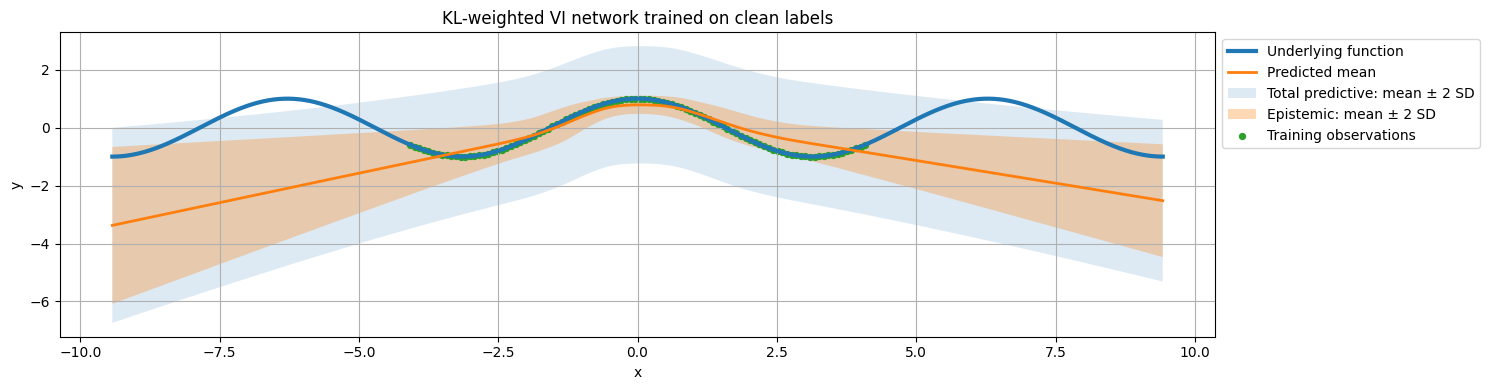

In [63]:
# vi_opt_state is the unchanged INITIAL state: this is a fresh fit, not fine-tuning.
params_vi_clean, train_objective_vi_clean, test_expected_nll_vi_clean = run_vi_training_loop(
    vi_num_epochs, vi_opt_state, X_train, Y_train_true, X_test, Y_test_true,
    vi_train_key, vi_eval_key, kl_prior_mean, kl_prior_sigma, kl_weight,
    likelihood_variance)
prediction_vi_clean = visualize_VI(
    params_vi_clean, X_train, Y_train_true,
    "KL-weighted VI network trained on clean labels",
    vi_plot_key, num_trials=vi_mc_samples, likelihood_variance=likelihood_variance)

Epoch 1 | T: 0.0035s | Train objective (sum NLL + beta KL): 188.8113 | Clean-test expected NLL/point: 1.2513
Epoch 50 | T: 0.0025s | Train objective (sum NLL + beta KL): 165.8737 | Clean-test expected NLL/point: 1.8388
Epoch 100 | T: 0.0028s | Train objective (sum NLL + beta KL): 157.1732 | Clean-test expected NLL/point: 1.5384
Epoch 150 | T: 0.0028s | Train objective (sum NLL + beta KL): 150.0715 | Clean-test expected NLL/point: 1.6443
Epoch 200 | T: 0.0032s | Train objective (sum NLL + beta KL): 139.7288 | Clean-test expected NLL/point: 3.0182
Epoch 250 | T: 0.0028s | Train objective (sum NLL + beta KL): 131.1834 | Clean-test expected NLL/point: 1.7666
interpolation: posterior-mean clean MSE=0.103215, mean epistemic SD=0.234905, mean total SD=1.028307
extrapolation: posterior-mean clean MSE=2.816704, mean epistemic SD=0.627932, mean total SD=1.189421


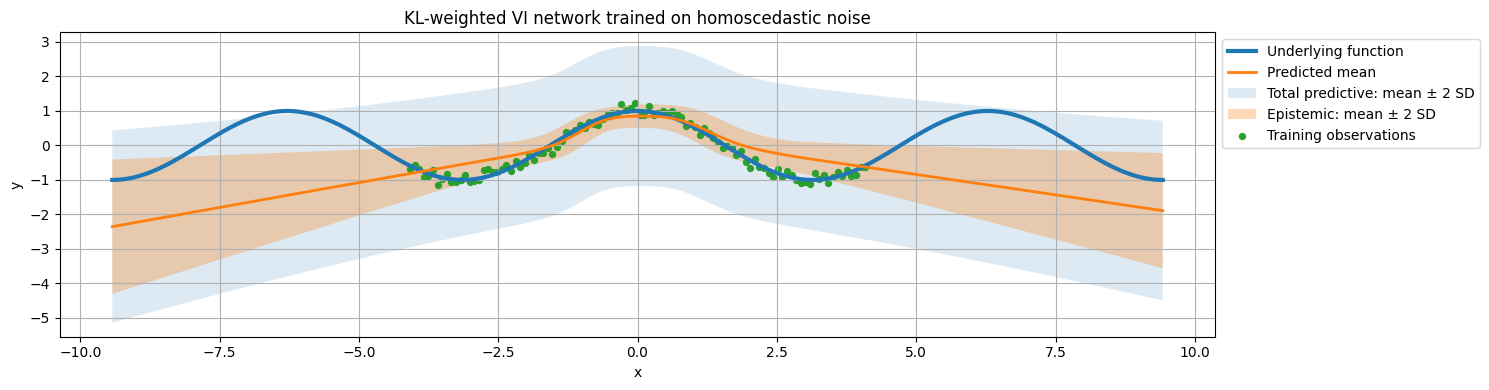

In [64]:
# vi_opt_state is the unchanged INITIAL state: this is a fresh fit, not fine-tuning.
params_vi_hom, train_objective_vi_hom, test_expected_nll_vi_hom = run_vi_training_loop(
    vi_num_epochs, vi_opt_state, X_train, Y_train_hom, X_test, Y_test_true,
    vi_train_key, vi_eval_key, kl_prior_mean, kl_prior_sigma, kl_weight,
    likelihood_variance)
prediction_vi_hom = visualize_VI(
    params_vi_hom, X_train, Y_train_hom,
    "KL-weighted VI network trained on homoscedastic noise",
    vi_plot_key, num_trials=vi_mc_samples, likelihood_variance=likelihood_variance)

Epoch 1 | T: 0.0040s | Train objective (sum NLL + beta KL): 188.0309 | Clean-test expected NLL/point: 1.2507
Epoch 50 | T: 0.0028s | Train objective (sum NLL + beta KL): 164.8008 | Clean-test expected NLL/point: 1.6723
Epoch 100 | T: 0.0030s | Train objective (sum NLL + beta KL): 160.3991 | Clean-test expected NLL/point: 3.2304
Epoch 150 | T: 0.0028s | Train objective (sum NLL + beta KL): 145.1175 | Clean-test expected NLL/point: 1.8297
Epoch 200 | T: 0.0031s | Train objective (sum NLL + beta KL): 134.7732 | Clean-test expected NLL/point: 2.6926
Epoch 250 | T: 0.0027s | Train objective (sum NLL + beta KL): 128.3649 | Clean-test expected NLL/point: 2.2746
interpolation: posterior-mean clean MSE=0.057955, mean epistemic SD=0.239568, mean total SD=1.029984
extrapolation: posterior-mean clean MSE=4.492629, mean epistemic SD=0.669157, mean total SD=1.212860


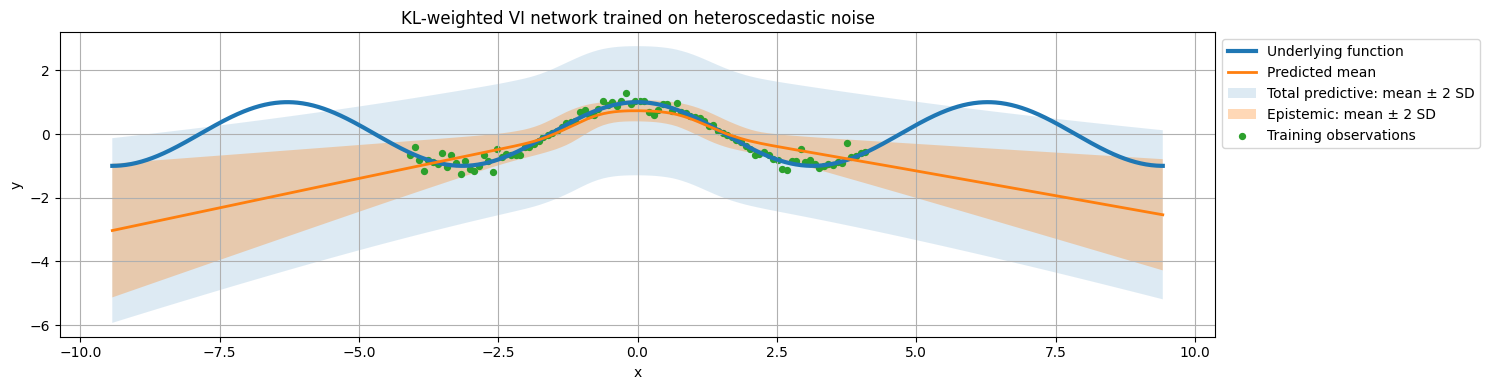

In [65]:
# vi_opt_state is the unchanged INITIAL state: this is a fresh fit, not fine-tuning.
params_vi_het, train_objective_vi_het, test_expected_nll_vi_het = run_vi_training_loop(
    vi_num_epochs, vi_opt_state, X_train, Y_train_het, X_test, Y_test_true,
    vi_train_key, vi_eval_key, kl_prior_mean, kl_prior_sigma, kl_weight,
    likelihood_variance)
prediction_vi_het = visualize_VI(
    params_vi_het, X_train, Y_train_het,
    "KL-weighted VI network trained on heteroscedastic noise",
    vi_plot_key, num_trials=vi_mc_samples, likelihood_variance=likelihood_variance)

### Interpreting the VI results
**Epistemic behavior.** Compare the estimated function variability inside and outside the training interval. More uncertainty away from observed data is a useful behavior to investigate, **not a correctness guarantee**. A valid implementation can be overconfident outside the training range because of its architecture, prior, variational family, or optimization. Neither Bayesian inference nor a mean-field approximation guarantees monotonic uncertainty growth with distance.

**Aleatoric versus total uncertainty.** The darker band reflects variation in $f_\theta(x)$ over sampled weights. The wider band additionally includes the fixed $c^2=1$. This assumed observation variance is not learned and does not match either noisy-data generator; in particular it cannot reproduce the heteroscedastic noise profile. The labels on these bands describe components of the fitted model, not certified calibration.

**Fit and approximation.** A weak mean fit can reflect the tight prior, single-sample training noise, limited training, and the chosen KL coefficient. Inspect the objective and predictions rather than treating poor fit as proof that the implementation is correct. Increasing prediction-time samples reduces Monte Carlo error, not inference bias. Use these results to discuss the limitations of this simplified KL-weighted, mean-field treatment.

For each dataset, explain what the two bands represent, whether the mean fits the observed region, and how the estimated epistemic variability changes outside that region. State the assumptions that prevent these plots alone from demonstrating calibrated uncertainty.

For a discussion of limitations of variational uncertainty estimates, see Foong et al., [On the Expressiveness of Approximate Inference in Bayesian Neural Networks](https://arxiv.org/abs/1909.00719), NeurIPS 2020. Their results distinguish shallow-network representational restrictions from inference problems that can persist in deeper networks.

### Answers from the saved Kaggle run
The table summarizes 100 prediction-time weight samples. MSE compares the sampled predictive mean with the clean cosine; standard deviations are averaged over inputs in each region.

| Training labels | Interpolation MSE | Extrapolation MSE | Epistemic SD inside | Epistemic SD outside | Total SD inside | Total SD outside |
| --- | --- | --- | --- | --- | --- | --- |
| Clean | 0.062661 | 5.031287 | 0.294283 | 0.820505 | 1.046542 | 1.306966 |
| Homoscedastic | 0.103215 | 2.816704 | 0.234905 | 0.627932 | 1.028307 | 1.189421 |
| Heteroscedastic | 0.057955 | 4.492629 | 0.239568 | 0.669157 | 1.029984 | 1.212860 |

- **Clean data:** the mean captures the broad central cosine shape but is less accurate inside the observed interval than the deterministic fit (MSE 0.062661 versus 0.000093). Outside, mean MSE grows to 5.031287 while average epistemic SD grows from 0.294283 to 0.820505.
- **Homoscedastic noise:** the mean broadly fits the observed region, with interpolation MSE 0.103215, but does not reproduce the periodic continuation. Epistemic SD increases from 0.234905 inside to 0.627932 outside; extrapolation MSE is 2.816704.
- **Heteroscedastic noise:** interpolation MSE is 0.057955 and extrapolation MSE is 4.492629. Epistemic SD increases from 0.239568 to 0.669157. The fixed observation variance cannot represent the true position-dependent noise, regardless of the apparent band coverage.

For **every dataset**, the narrower orange band is mean $\pm2$ epistemic SD from variability in sampled network functions. The wider blue band is mean $\pm2$ total SD, computed pointwise as $\sqrt{\operatorname{Var}_Q(f_\theta(x))+1}$. The observation SD is fixed at 1, even for clean data, so the total bands are much wider than the data-generating noise warrants. One must combine variances pointwise before taking square roots and averaging; squaring the regional mean epistemic SD does not reproduce the regional mean total SD.

All three runs show larger average epistemic variability outside the observed interval, but also substantial extrapolation errors. The variational family, tight prior, finite optimization, one-sample gradient estimates, $\beta=10^{-4}$ and misspecified fixed likelihood variance limit the interpretation. More Monte Carlo predictions reduce sampling error but do not fix these modeling assumptions. The plotted bands and clean test curve alone therefore do not establish calibrated predictive coverage.


Finally, approximately how long did it take you to complete this practical?

The full practical took me **12 hours** (Understanding how jax works consumed some time)

## Reflection on LLM use and learning

### 1. Which LLM I used and how
I used OpenAI Codex, a GPT-6-based assistant, as a tutor, coding assistant and writing aid during this practical. My use went beyond formatting: it included explanations, implementation suggestions, generated code, debugging, and help drafting interpretations and this reflection.

For the mathematics, I asked the assistant to convert equations into LaTeX that I could paste into notebook Markdown cells. I also asked it to explain the intermediate steps in the Gaussian KL derivation: expanding the two log densities and taking expectations under $Q_\omega(\theta)$. In particular, the identities $\mathbb E_Q[(\theta_j-\mu_j)^2]=\sigma_j^2$ and $\mathbb E_Q[\theta_j^2]=\mu_j^2+\sigma_j^2$ explain where the terms in the closed-form KL come from. Here $Q_\omega$ is the **approximate posterior**, while $P(\theta)$ is the prior. This distinction helped me connect the mathematical objective to the implementation.

The assistant explained variable types, array shapes, and the supplied helper functions, allowing me to focus on how they fit into the TODO components. It helped implement the VI loss and reparameterized layer, completed ensemble/MIMO implementations and comparison code, and generated a self-contained JAX MNIST deep-ensemble extension because the referenced starter script was not available in my workspace. It also helped compare the saved results with the written discussions and corrected a variance-versus-standard-deviation error in my first written Gaussian derivation. I ran the notebooks on Kaggle and supplied the resulting files for review. Some earlier ensemble checks were run by the assistant locally; the final numerical discussions use the saved Kaggle results. The assistant helped draft this disclosure and prepare the PDF exports.

### 2. Benefits and limitations for my learning
The main benefit was reducing the time spent on unfamiliar JAX syntax, helper-function interfaces and equation formatting. Step-by-step explanations helped connect the probability distributions to executable operations: summing over observations, summing over parameter coordinates, applying softplus to standard deviations, and sampling with the reparameterization trick. This made it easier to concentrate on the purpose of each loss term and on the differences between aleatoric and epistemic uncertainty.

The main drawback is that receiving complete code can replace the practice of constructing and debugging an implementation myself. A notebook that runs is not evidence that I could reproduce every part unaided. Fluent explanations can also appear more reliable than they are. During this work, the written Gaussian derivation needed correction, and discussion values from an earlier run had to be replaced with the actual Kaggle outputs. These are reasons to check both the mathematics and the evidence rather than accept generated text automatically.

My assessment is that LLM support improved my access to the concepts and my ability to finish the experiments, but reduced the amount of independent implementation practice. To consolidate the learning, I should be able to derive the losses, explain the tensor shapes and trace the sampling and ensembling code without referring to the assistant. I regard generated code as something I must understand and defend, not as evidence of mastery on its own.

### 3. Should LLM use be allowed?
I support allowing LLMs in practical assignments with transparent disclosure and responsibility for the submitted work. They can help students overcome programming and notation barriers while exploring the intended concepts. However, unrestricted copying without understanding would weaken the learning objective and make assessment less informative.

A useful policy would distinguish tutoring, formatting, debugging and code generation, and require students to state which forms of help they used. Students should verify generated claims against their actual experiments and be prepared to explain a derivation or modify part of the implementation independently. Short oral questions or an unaided component could assess that understanding. This would preserve the educational benefits of LLM assistance while assessing what the student has learned, rather than only the quality of the final generated notebook.
